In [2]:
# Core library imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile as tiff
import torch


# Dice over time (in binary)

In [15]:
# Load video frames
frames_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02").iterdir())
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir())

#TODO add : for idx in range(len(seg_path_list) - 1):
res_dice = {}
res_iou = {}
for gap in range(1, len(frames_path_list) - 1):
    idx = 0
    idx2 = idx + gap
    seg_moving = tiff.imread(seg_path_list[idx])
    seg_fixed = tiff.imread(seg_path_list[idx2])
    seg_moving = np.where(seg_moving > 0, 1, 0)
    seg_fixed = np.where(seg_fixed > 0, 1, 0)
    seg_moving = interpole_and_pad(seg_moving, [HEIGHT, WIDTH])
    seg_fixed = interpole_and_pad(seg_fixed, [HEIGHT, WIDTH])
    # Check if nbr of cells different
    labels_moving = np.sort(np.unique(seg_moving))
    labels_fixed = np.sort(np.unique(seg_fixed))
    if len(labels_moving) != len(labels_fixed):
        print(  # noqa: T201
            f"Different number of cells for pair {idx}-{idx2} {len(labels_moving)} vs {len(labels_fixed)}, skipping evaluation for this pair."  # noqa: E501
        )
        continue
    # Compute Dice score
    dice = vxm.py.utils.dice(seg_moving, seg_fixed, include_zero=False)
    res_dice[f"{gap}"] = np.mean(dice)
    # Compute IoU score
    iou_score = iou(seg_moving, seg_fixed, include_zero=False)
    res_iou[f"{gap}"] = np.mean(iou_score)

print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201

Dice scores: {'1': np.float64(0.9439700997774653), '2': np.float64(0.9127310061601642), '3': np.float64(0.8722453099804665), '4': np.float64(0.8336712174091563), '5': np.float64(0.8163752962678326), '6': np.float64(0.7935098273090286), '7': np.float64(0.7687639006866858), '8': np.float64(0.7468677554635201), '9': np.float64(0.7328324596916483), '10': np.float64(0.7118122598329989), '11': np.float64(0.7116481867229043), '12': np.float64(0.6846643360636496), '13': np.float64(0.7043389443803308), '14': np.float64(0.697715928998777), '15': np.float64(0.6930088384918625), '16': np.float64(0.6746675273520093), '17': np.float64(0.6506859641188), '18': np.float64(0.6309371530235246), '19': np.float64(0.6071092794127118), '20': np.float64(0.5926516743184707), '21': np.float64(0.5757281049819757), '22': np.float64(0.555243985198274), '23': np.float64(0.5412018940477326), '24': np.float64(0.526644606559262), '25': np.float64(0.5208416642863943), '26': np.float64(0.5094836169011941), '27': np.floa

Dice scores: {'1': np.float64(0.9439700997774653), '2': np.float64(0.9127310061601642), '3': np.float64(0.8722453099804665), '4': np.float64(0.8336712174091563), '5': np.float64(0.8163752962678326), '6': np.float64(0.7935098273090286), '7': np.float64(0.7687639006866858), '8': np.float64(0.7468677554635201), '9': np.float64(0.7328324596916483), '10': np.float64(0.7118122598329989), '11': np.float64(0.7116481867229043), '12': np.float64(0.6846643360636496), '13': np.float64(0.7043389443803308), '14': np.float64(0.697715928998777), '15': np.float64(0.6930088384918625), '16': np.float64(0.6746675273520093), '17': np.float64(0.6506859641188), '18': np.float64(0.6309371530235246), '19': np.float64(0.6071092794127118), '20': np.float64(0.5926516743184707), '21': np.float64(0.5757281049819757), '22': np.float64(0.555243985198274), '23': np.float64(0.5412018940477326), '24': np.float64(0.526644606559262), '25': np.float64(0.5208416642863943), '26': np.float64(0.5094836169011941), '27': np.floa

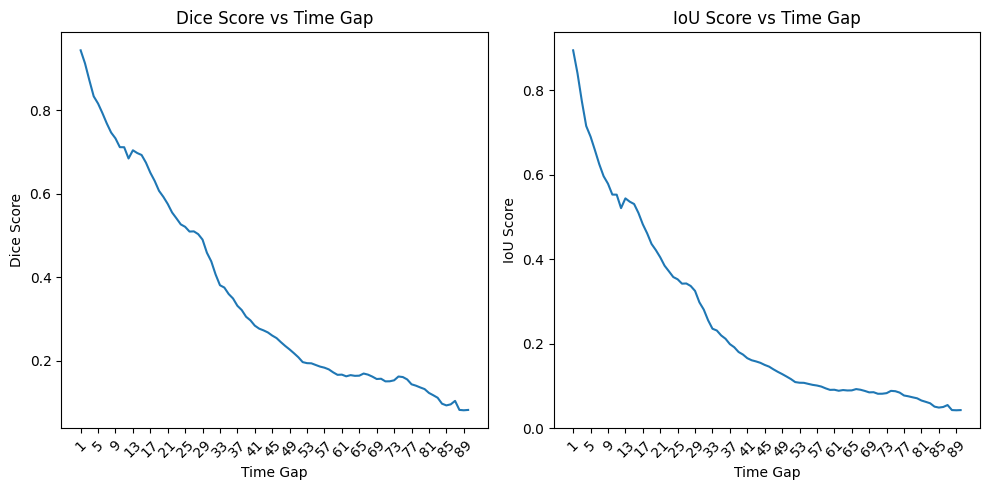

In [16]:
print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201
# Plot results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(list(res_dice.keys()), list(res_dice.values()))
plt.xlabel("Time Gap")
plt.ylabel("Dice Score")
plt.title("Dice Score vs Time Gap")
plt.xticks(list(res_dice.keys())[::4], rotation=45)
plt.subplot(1, 2, 2)
plt.plot(list(res_iou.keys()), list(res_iou.values()))
plt.xlabel("Time Gap")
plt.ylabel("IoU Score")
plt.title("IoU Score vs Time Gap")
plt.xticks(list(res_iou.keys())[::4], rotation=45)
plt.tight_layout()
plt.show()

# Dice over time (with ERR_SEG_TRA)

In [17]:
# Load video frames
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA").iterdir())

#TODO add : for idx in range(len(seg_path_list) - 1):
res_dice = {}
res_iou = {}
for gap in range(1, len(seg_path_list) - 1):
    idx = 0
    idx2 = idx + gap
    seg_moving = tiff.imread(seg_path_list[idx])
    seg_fixed = tiff.imread(seg_path_list[idx2])
    seg_moving = interpole_and_pad(seg_moving, [HEIGHT, WIDTH])
    seg_fixed = interpole_and_pad(seg_fixed, [HEIGHT, WIDTH])
    # Compute Dice score
    dice = vxm.py.utils.dice(seg_moving, seg_fixed, include_zero=False)
    res_dice[f"{gap}"] = np.mean(dice)
    # Compute IoU score
    iou_score = iou(seg_moving, seg_fixed, include_zero=False)
    res_iou[f"{gap}"] = np.mean(iou_score)

print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201

Dice scores: {'1': np.float64(0.9399053565398419), '2': np.float64(0.9068198855952209), '3': np.float64(0.864410832858282), '4': np.float64(0.7700566476613145), '5': np.float64(0.7788832719742307), '6': np.float64(0.7511502250888499), '7': np.float64(0.7247051544985782), '8': np.float64(0.7312115021547118), '9': np.float64(0.6946923045679031), '10': np.float64(0.6859820178525292), '11': np.float64(0.704142494759833), '12': np.float64(0.6590321022803447), '13': np.float64(0.6797303516291269), '14': np.float64(0.6730721011677624), '15': np.float64(0.6701209543701304), '16': np.float64(0.652988009581195), '17': np.float64(0.60614450546129), '18': np.float64(0.5671594295985725), '19': np.float64(0.5280452887650176), '20': np.float64(0.5319356937068834), '21': np.float64(0.5161850893552526), '22': np.float64(0.48210453468496156), '23': np.float64(0.47339565633651626), '24': np.float64(0.47805523788540727), '25': np.float64(0.4718074110277704), '26': np.float64(0.4613093296362862), '27': np.

Dice scores: {'1': np.float64(0.9399053565398419), '2': np.float64(0.9068198855952209), '3': np.float64(0.864410832858282), '4': np.float64(0.7700566476613145), '5': np.float64(0.7788832719742307), '6': np.float64(0.7511502250888499), '7': np.float64(0.7247051544985782), '8': np.float64(0.7312115021547118), '9': np.float64(0.6946923045679031), '10': np.float64(0.6859820178525292), '11': np.float64(0.704142494759833), '12': np.float64(0.6590321022803447), '13': np.float64(0.6797303516291269), '14': np.float64(0.6730721011677624), '15': np.float64(0.6701209543701304), '16': np.float64(0.652988009581195), '17': np.float64(0.60614450546129), '18': np.float64(0.5671594295985725), '19': np.float64(0.5280452887650176), '20': np.float64(0.5319356937068834), '21': np.float64(0.5161850893552526), '22': np.float64(0.48210453468496156), '23': np.float64(0.47339565633651626), '24': np.float64(0.47805523788540727), '25': np.float64(0.4718074110277704), '26': np.float64(0.4613093296362862), '27': np.

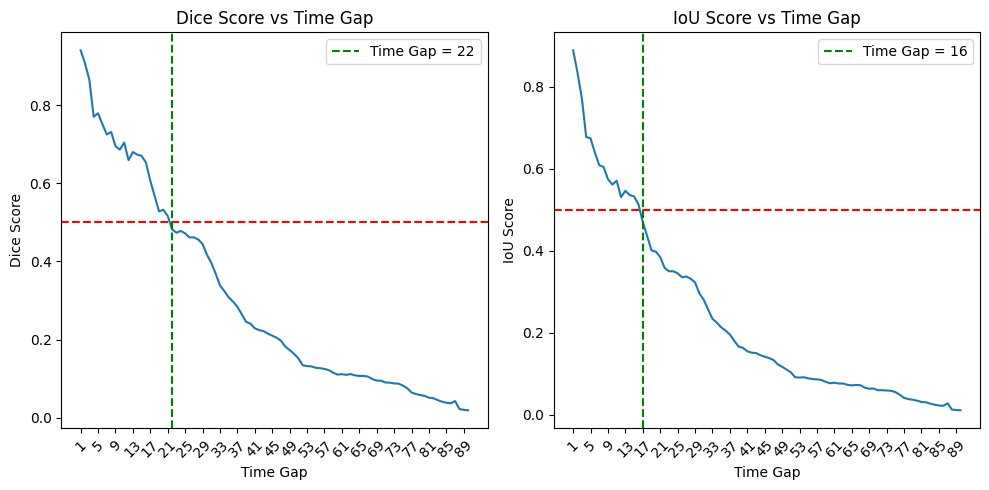

In [28]:
print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201
# Plot results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(list(res_dice.keys()), list(res_dice.values()))
plt.xlabel("Time Gap")
plt.ylabel("Dice Score")
plt.title("Dice Score vs Time Gap")
plt.xticks(list(res_dice.keys())[::4], rotation=45)
plt.axhline(y=0.5, color="r", linestyle="--")
plt.axvline(x=21, color="g", linestyle="--", label="Time Gap = 22")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(list(res_iou.keys()), list(res_iou.values()))
plt.xlabel("Time Gap")
plt.ylabel("IoU Score")
plt.title("IoU Score vs Time Gap")
plt.xticks(list(res_iou.keys())[::4], rotation=45)
plt.axhline(y=0.5, color="r", linestyle="--")
plt.axvline(x=16, color="g", linestyle="--", label="Time Gap = 16")
plt.legend()
plt.tight_layout()
plt.show()

# Visualisation over time

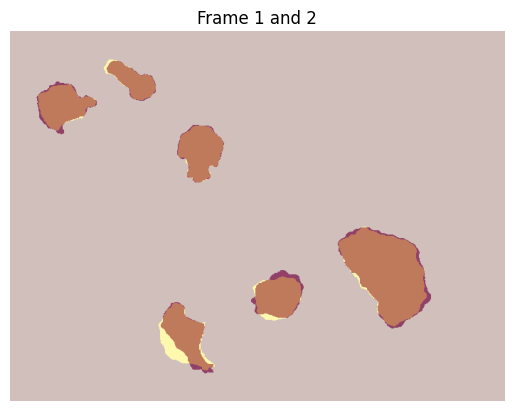

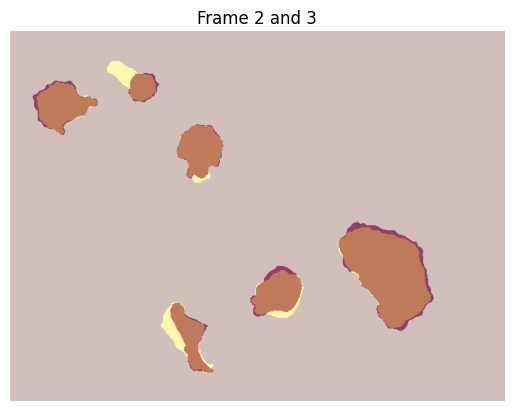

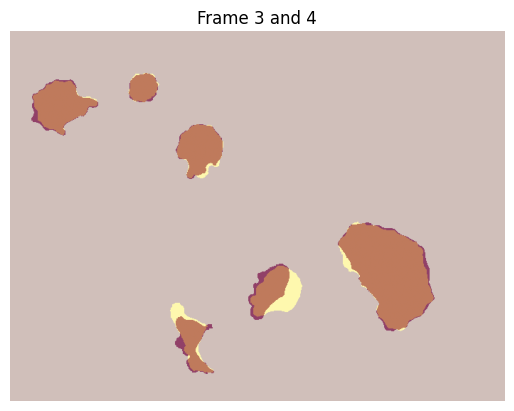

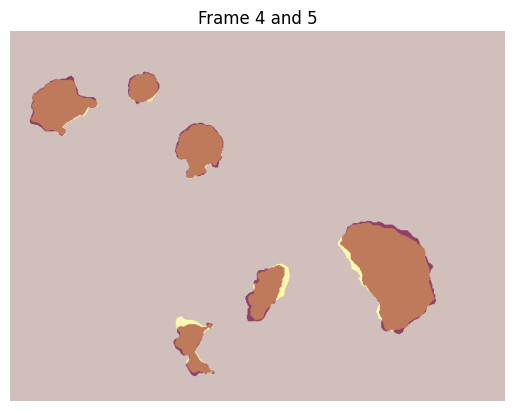

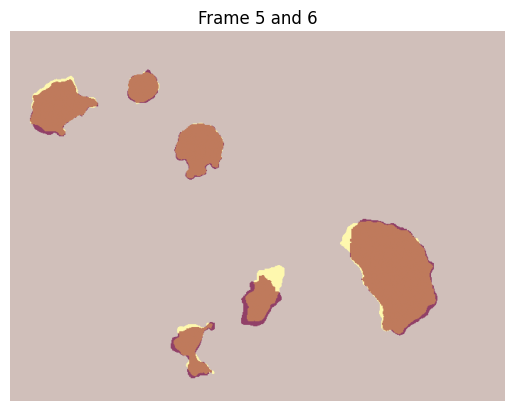

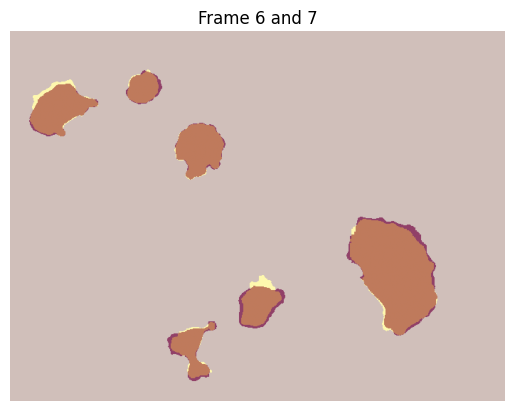

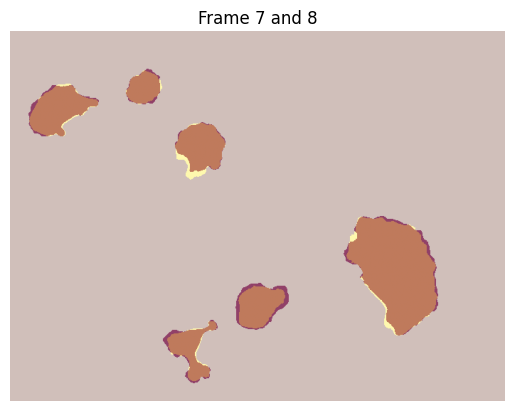

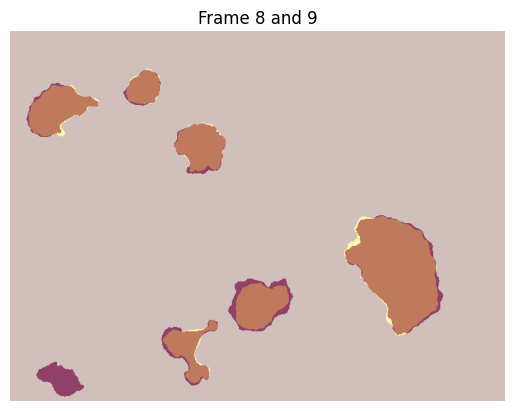

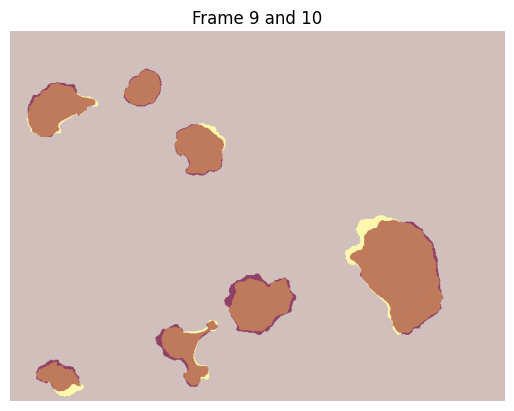

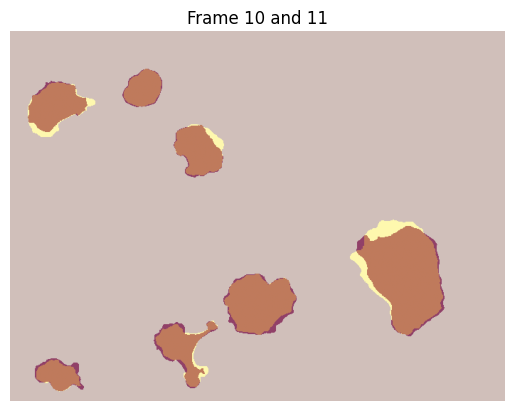

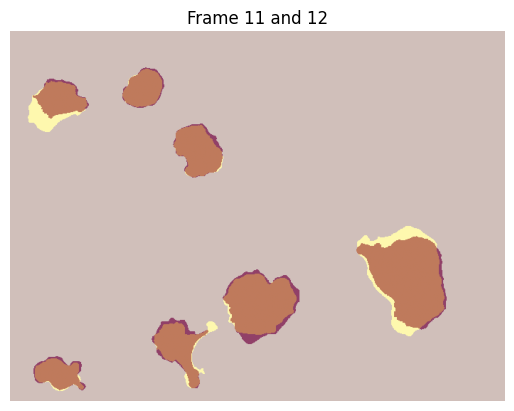

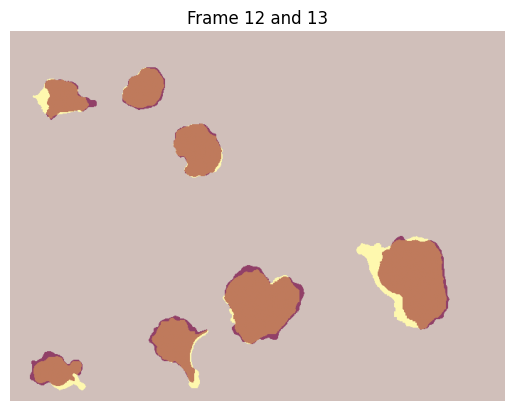

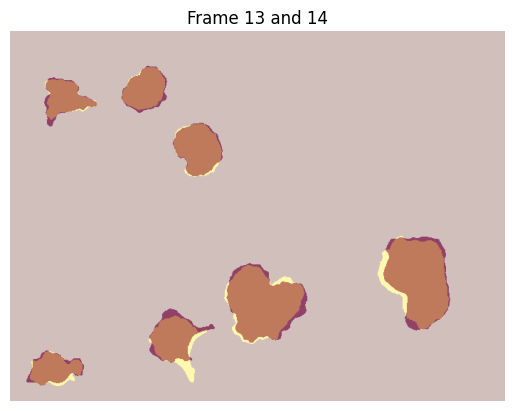

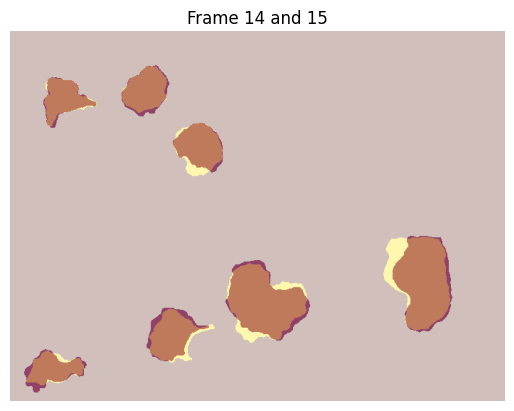

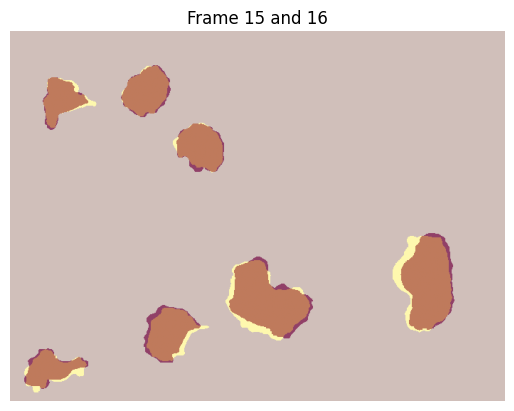

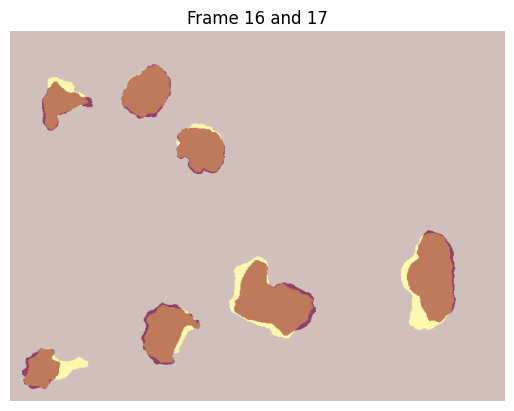

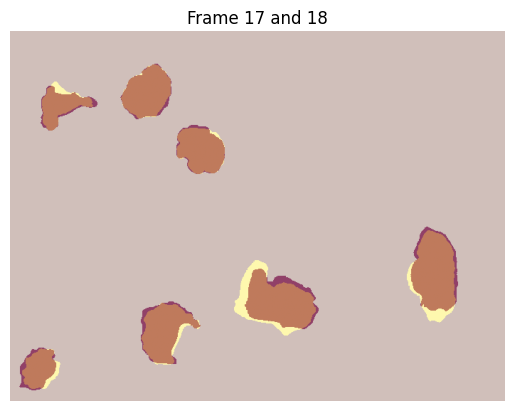

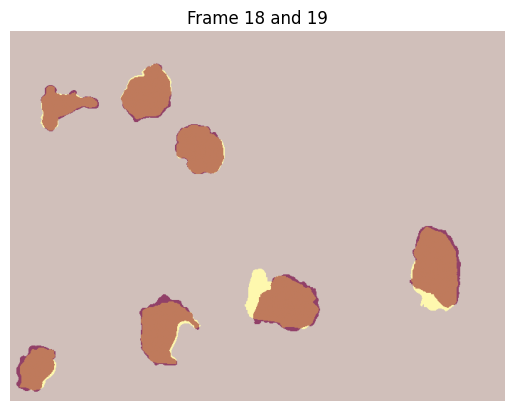

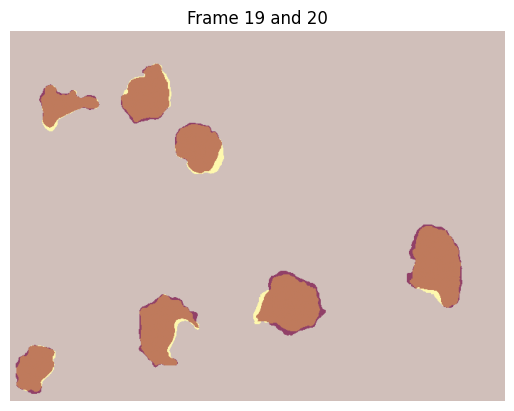

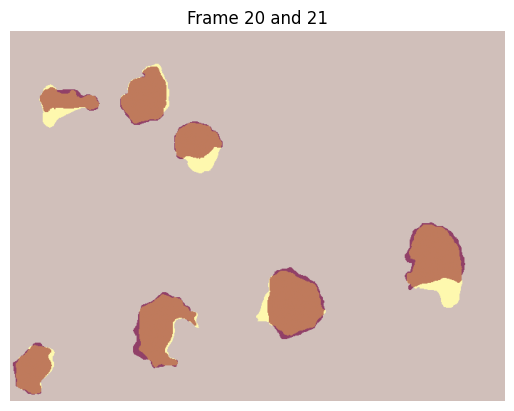

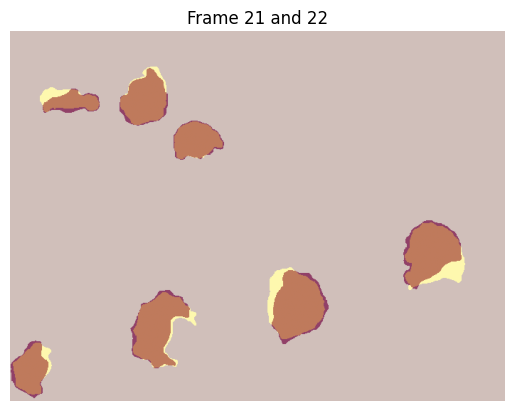

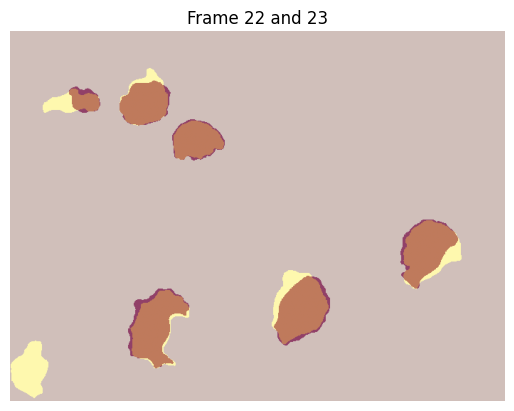

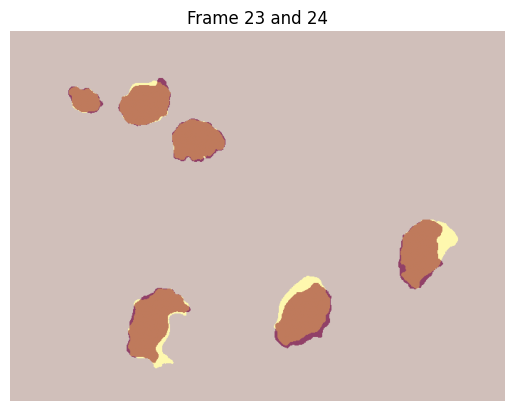

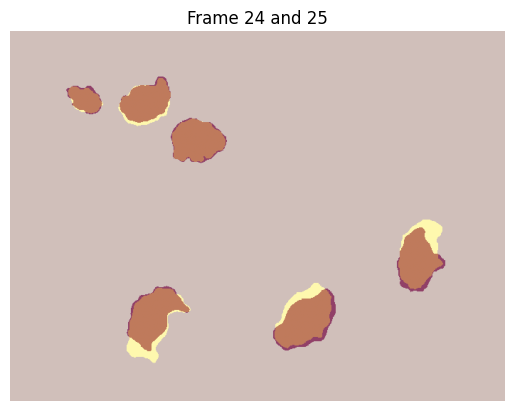

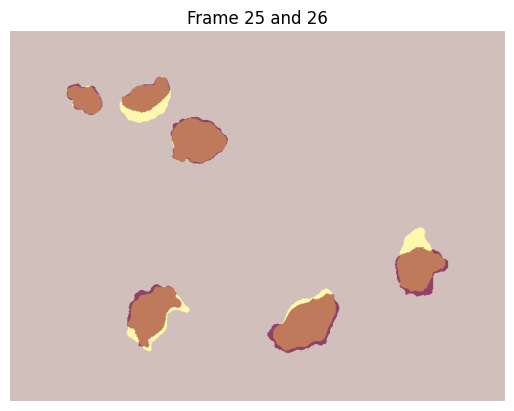

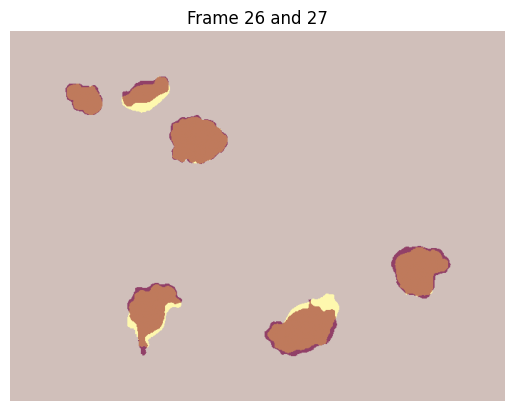

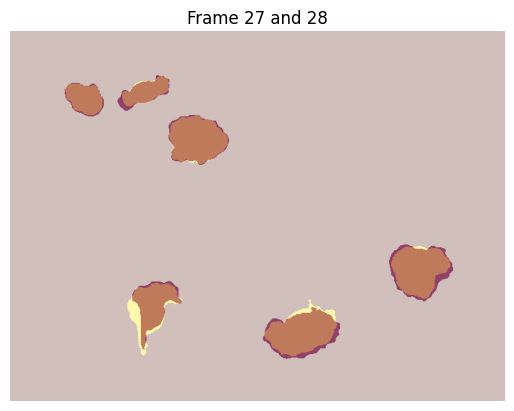

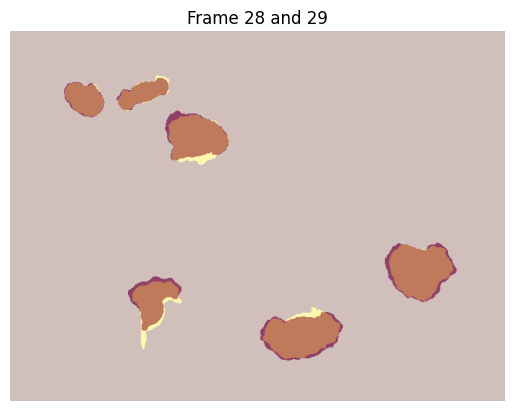

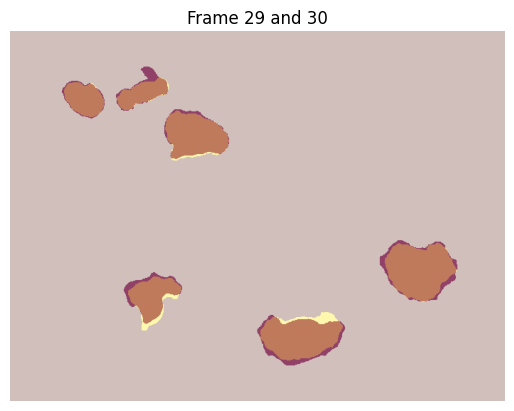

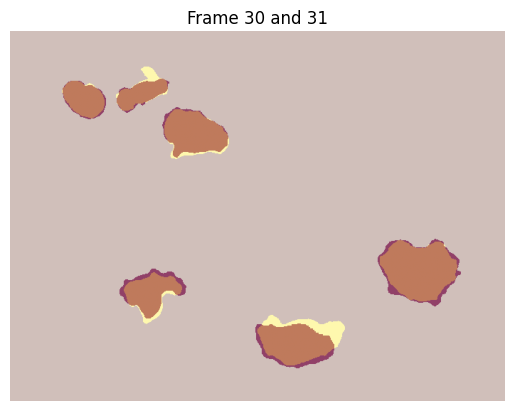

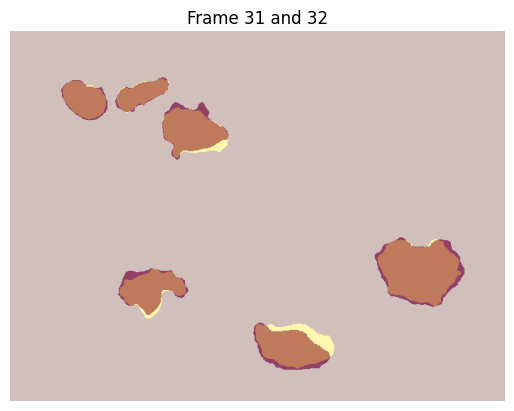

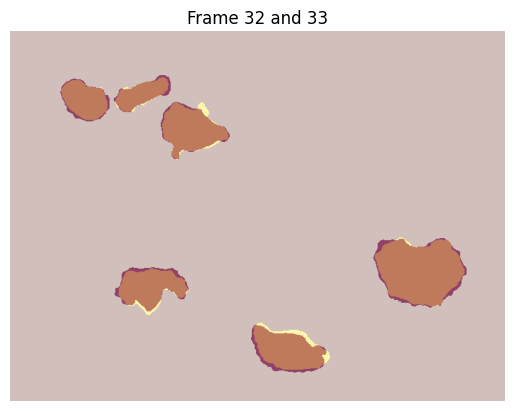

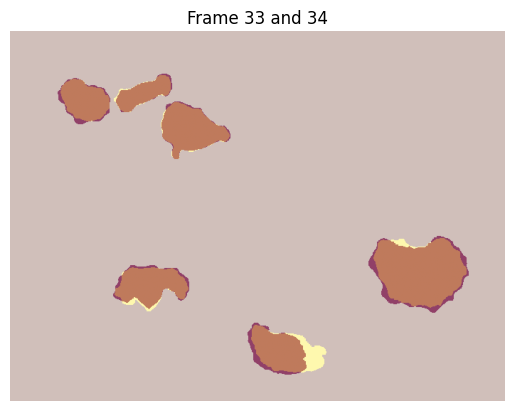

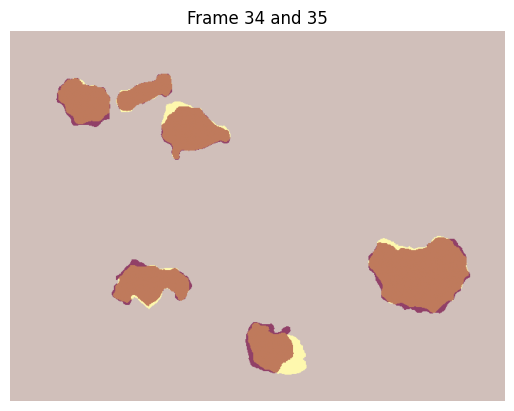

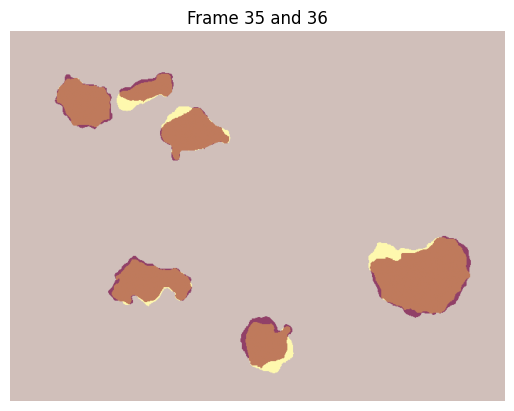

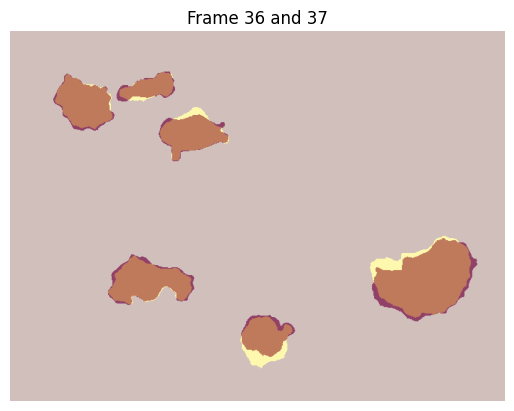

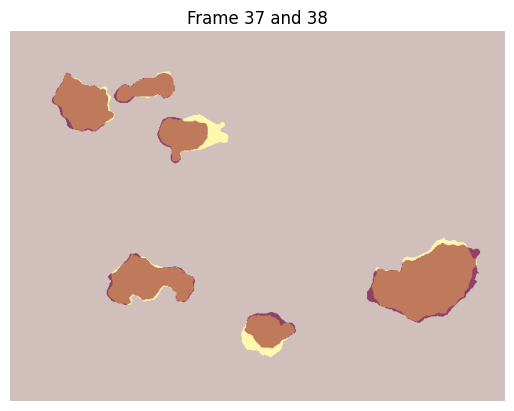

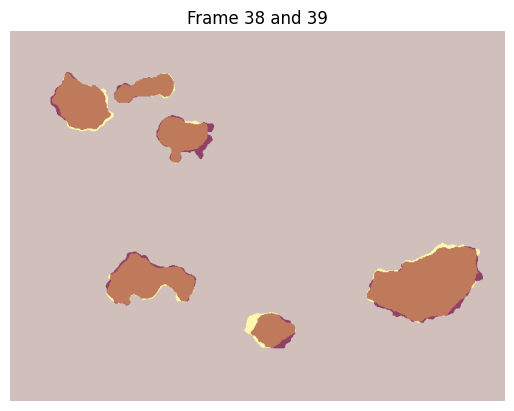

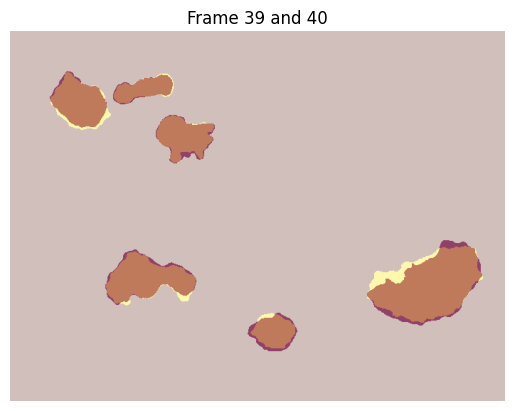

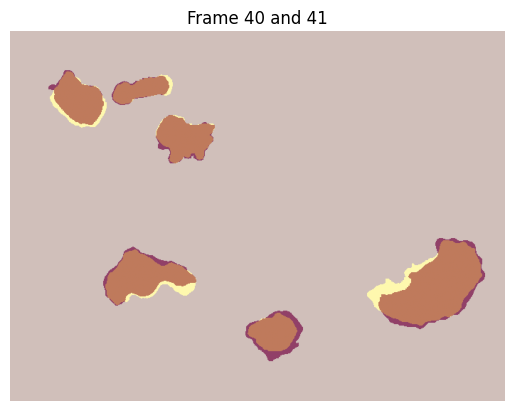

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile as tiff

# from src.my_utils.image_utils import interpole_and_pad

# Load video frames
seg_path_list = sorted(Path("data/data/PhC-C2DH-U373/01_ERR_SEG_TRA").iterdir())

#TODO add : for idx in range(len(seg_path_list) - 1):
for i in range(1, 41):
    idx = i
    idx2 = idx + 1
    seg_moving = tiff.imread(seg_path_list[idx])
    seg_fixed = tiff.imread(seg_path_list[idx2])
    # seg_moving = interpole_and_pad(seg_moving, [HEIGHT, WIDTH])
    # seg_fixed = interpole_and_pad(seg_fixed, [HEIGHT, WIDTH])
    seg_moving = np.where(seg_moving > 0, 1, 0)
    seg_fixed = np.where(seg_fixed > 0, 1, 0)
    plt.imshow(seg_moving, alpha=0.5)
    plt.imshow(seg_fixed, cmap="YlOrRd", alpha=0.5)
    plt.title(f"Frame {idx} and {idx2}")
    plt.axis("off")
    plt.show()

# Label visualisation

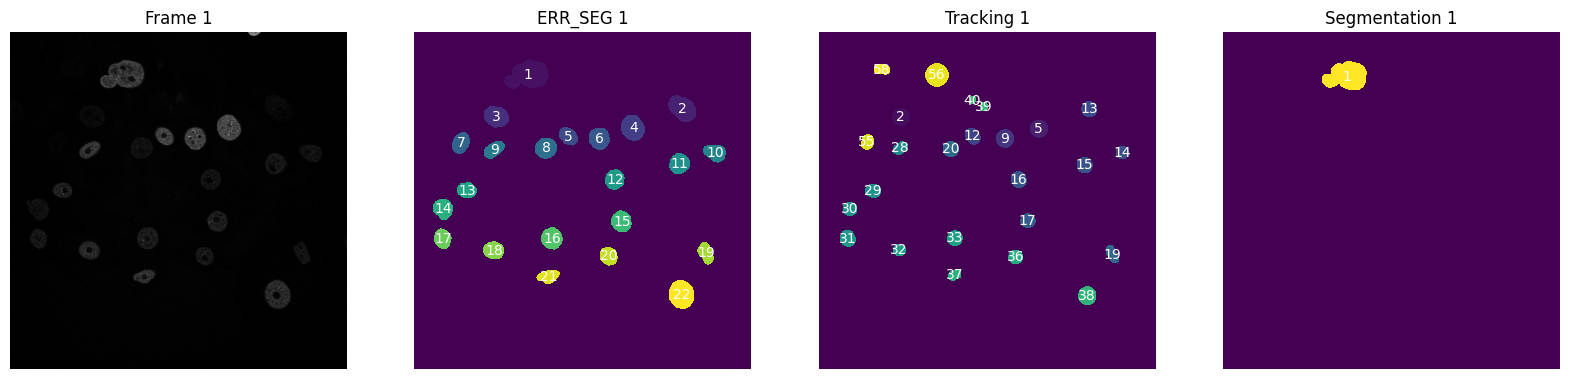

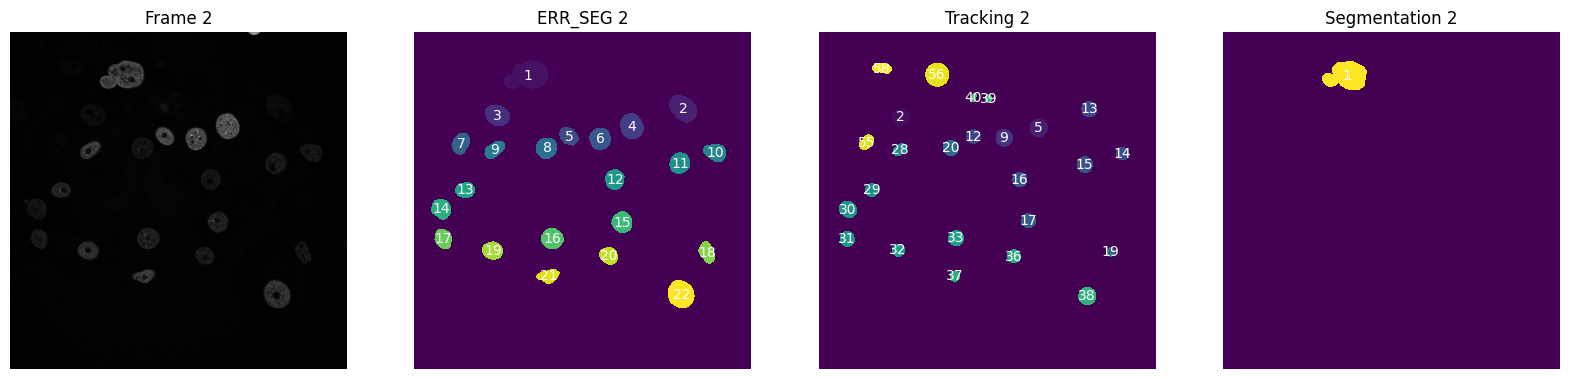

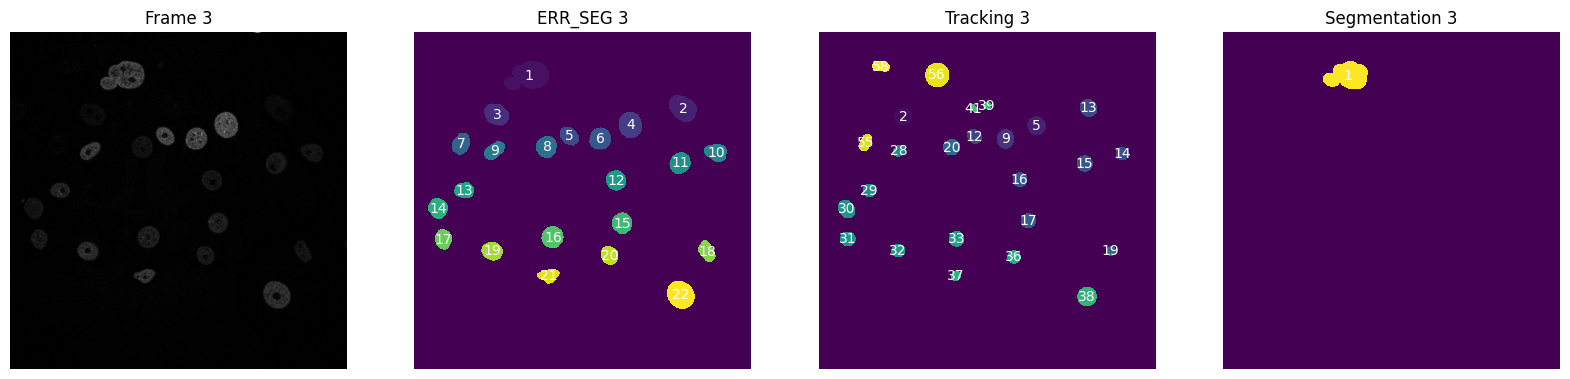

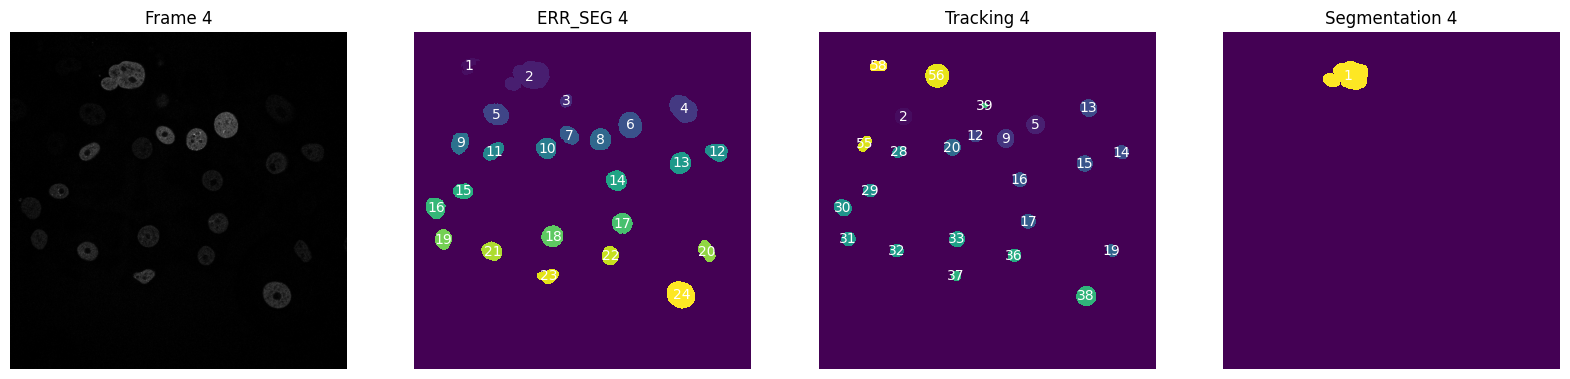

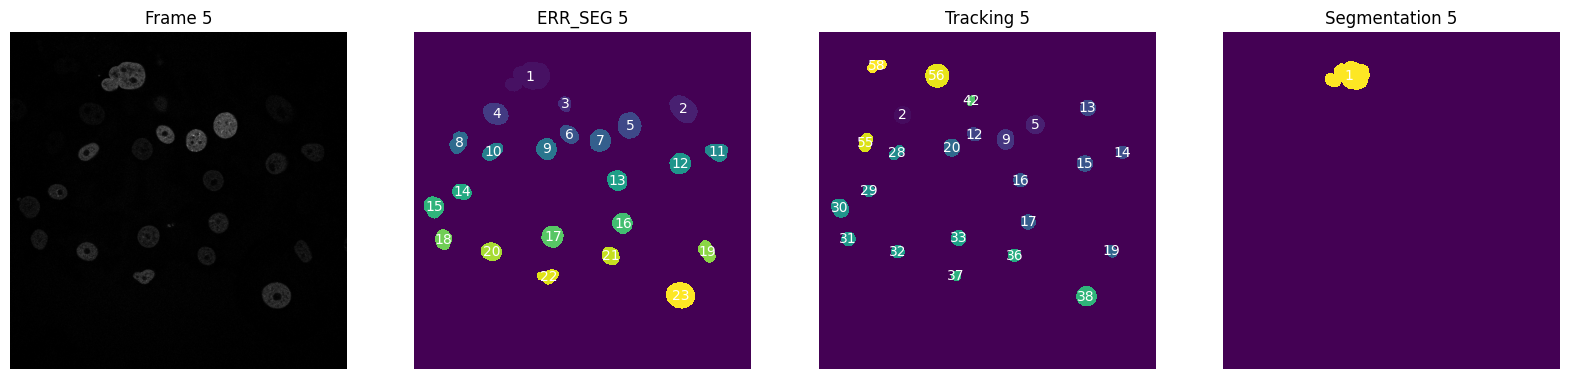

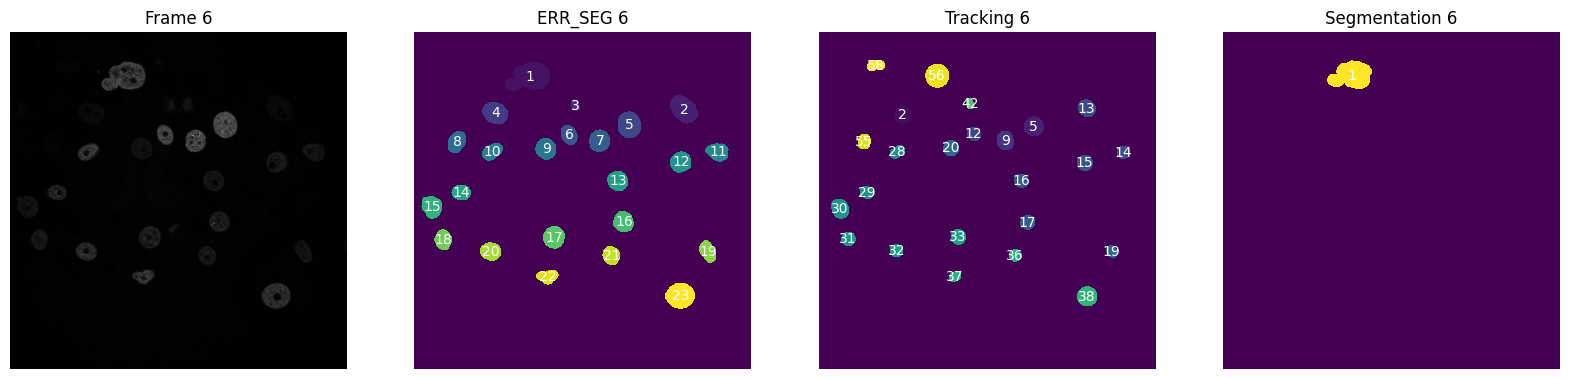

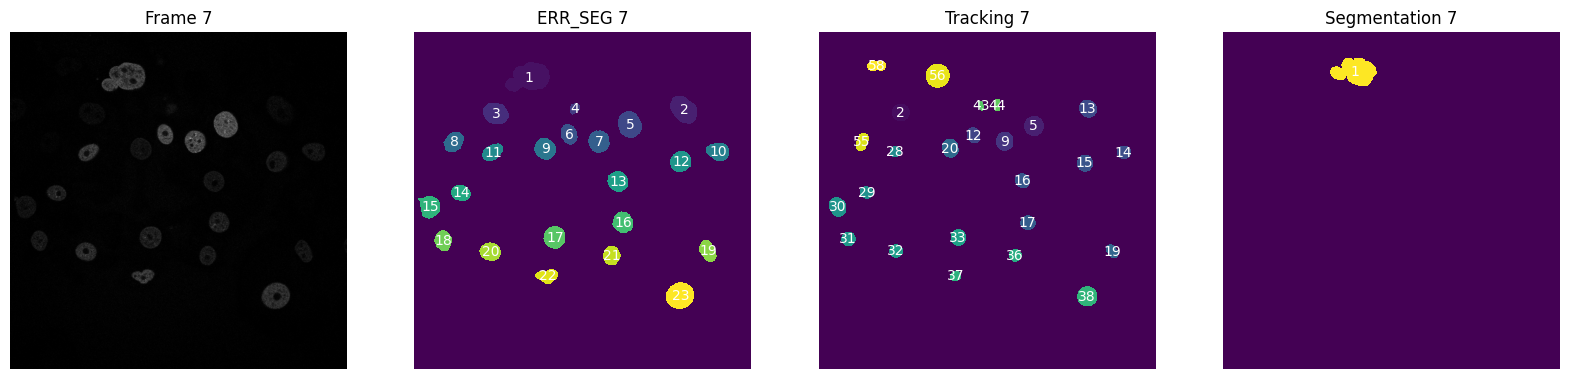

In [20]:
img_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02").iterdir())
err_seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir())
tra_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_GT/TRA").iterdir())
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_GT/SEG").iterdir())

for idx in range(1, 8):
    fig, axes = plt.subplots(1,4,figsize=(20, 5))
    img = tiff.imread(img_path_list[idx])
    axes[0].imshow(img, cmap="gray")
    axes[0].set_title(f"Frame {idx}")
    axes[0].axis("off")

    err_seg = tiff.imread(err_seg_path_list[idx])
    axes[1].set_title(f"ERR_SEG {idx}")
    visualize_labels(err_seg, ax=axes[1])

    tra = tiff.imread(tra_path_list[idx])
    axes[2].set_title(f"Tracking {idx}")
    visualize_labels(tra, ax=axes[2])

    seg = tiff.imread(seg_path_list[idx])
    axes[3].set_title(f"Segmentation {idx}")
    visualize_labels(seg, ax=axes[3])
    plt.show()


## Creation of ERR_SEG_TRA

Create new dataset with relabeled ERR_SEG using TRA

In [ ]:
# Fluo-N2DH-GOWT1 02
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/02_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

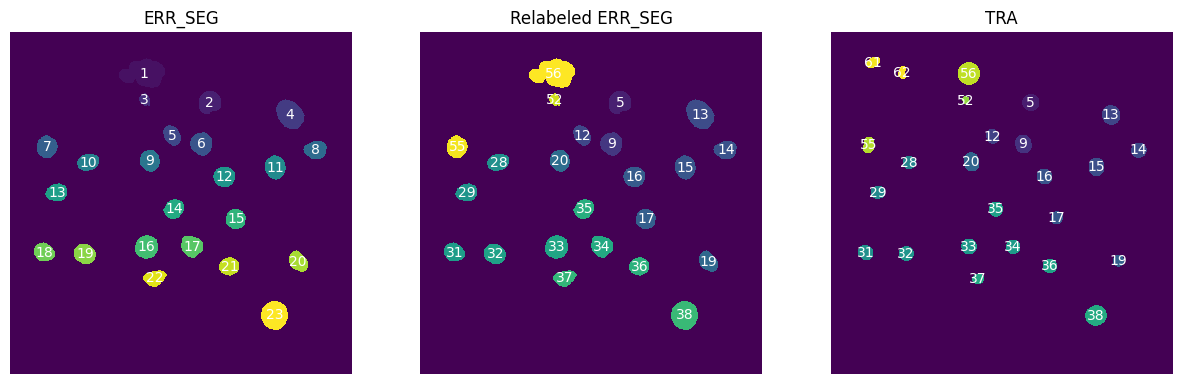

In [5]:
# Verification
from skimage.measure import regionprops


def visualize_labels(mask, ax=None):
    """Visualize a segmentation mask with written labels."""
    if ax is None:
        ax = plt.gca()
    ax.imshow(mask, interpolation="nearest")
    ax.axis("off")

    for region in regionprops(mask):
        if region.label == 0:
            continue
        y, x = region.centroid
        ax.text(
            x,
            y,
            str(region.label),
            color="white",
            fontsize=10,
            ha="center",
            va="center",
        )


idx = 34
err_seg_path_list = sorted(f for f in Path("data/data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/data/Fluo-N2DH-GOWT1_train/02_GT/TRA").iterdir() if f.suffix == ".tif")
err_seg = tiff.imread(err_seg_path_list[idx])
tra = tiff.imread(tra_path_list[idx])
err_seg_tra_path_list = sorted(Path("data/data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA").iterdir())
relabeled = tiff.imread(err_seg_tra_path_list[idx])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].set_title("ERR_SEG")
visualize_labels(err_seg, ax=ax[0])
ax[1].set_title("Relabeled ERR_SEG")
visualize_labels(relabeled, ax=ax[1])
ax[2].set_title("TRA")
visualize_labels(tra, ax=ax[2])
plt.savefig("err_seg_tra.png")

In [30]:
# Fluo-N2DH-GOWT1 01
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/01_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/01_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DH-GOWT1_train/01_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

In [31]:
# Fluo-N2DL-HeLa_train 01
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/01_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/01_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DL-HeLa_train/01_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

In [ ]:
# Fluo-N2DL-HeLa_train 02 - ajout segmentation dans entrainement
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/02_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/02_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DL-HeLa_train/02_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

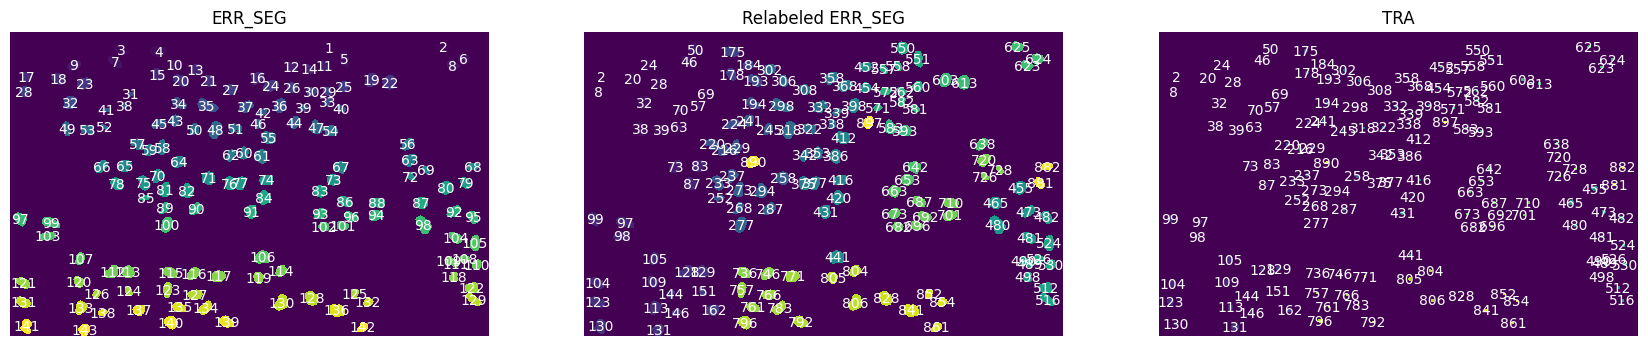

In [34]:
# Verification
idx = 4
err_seg = tiff.imread(err_seg_path_list[idx])
tra = tiff.imread(tra_path_list[idx])
err_seg_tra_path_list = sorted(Path("data/train_data/Fluo-N2DL-HeLa_train/02_ERR_SEG_TRA").iterdir())
relabeled = tiff.imread(err_seg_tra_path_list[idx])
fig, ax = plt.subplots(1, 3, figsize=(21, 7))
ax[0].set_title("ERR_SEG")
visualize_labels(err_seg, ax=ax[0])
ax[1].set_title("Relabeled ERR_SEG")
visualize_labels(relabeled, ax=ax[1])
ax[2].set_title("TRA")
visualize_labels(tra, ax=ax[2])

# To understand grid_sample / vxm.spatial_transform

In [24]:
input = torch.arange(4*4).view(1, 1, 4, 4).float()
print(input)

# Create grid to upsample input
d = torch.linspace(-1, 1, 4)
meshx, meshy = torch.meshgrid((d, d))
grid = torch.stack((meshy, meshx), 2)
grid = grid.unsqueeze(0) # add batch dim

# Create coordinate meshgrid
size = 4
y = np.linspace(-1, 1, size)
x = np.linspace(-1, 1, size)
yy, xx = np.meshgrid(y, x)

# Create deformation: radial outward displacement
# Distance from center
r = np.sqrt(xx**2 + yy**2)
# Radial deformation strength
deform_strength = 0.3
# Displacement components (pointing outward from center)
disp_y = deform_strength * yy / (r + 0.1)  # avoid division by zero
disp_x = deform_strength * xx / (r + 0.1)

# Create the deformed grid (original + displacement)
grid_y_deformed = yy + disp_y
grid = xx + disp_x
grid = torch.from_numpy(np.stack((grid_y_deformed, grid), axis=2)).float().unsqueeze(0)  # add batch dim

output = torch.nn.functional.grid_sample(input, grid, align_corners=True)
print(output)

output = torch.nn.functional.grid_sample(input, grid, mode="nearest", align_corners=True)
print(output)

tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]]]])
tensor([[[[ 0.0000,  0.5308,  1.2995,  1.4819],
          [ 2.1232,  3.6874,  5.2125,  3.9534],
          [ 5.1978,  9.7875, 11.3126,  7.0281],
          [ 5.9274,  7.8518,  8.6205,  7.4093]]]])
tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]]]])


NameError: name 'grid_x_deformed' is not defined

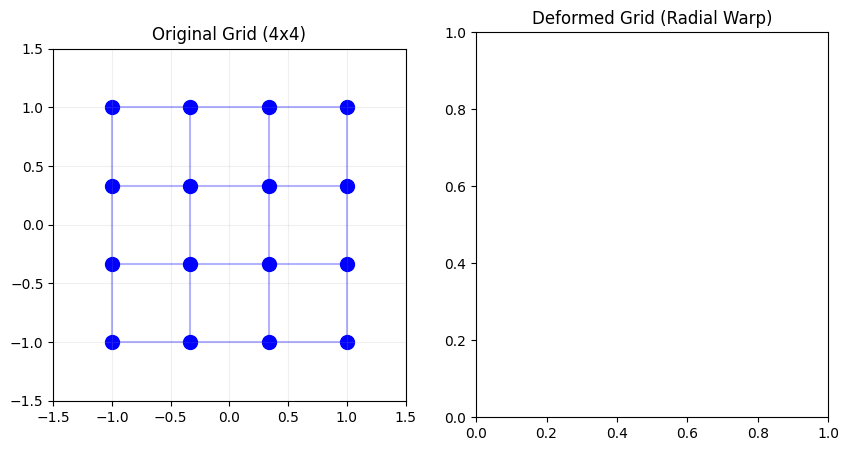

In [25]:
# Visualize with square subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Set common limits
xlim = (-1.5, 1.5)
ylim = (-1.5, 1.5)

# Original grid
axes[0].set_title('Original Grid (4x4)', fontsize=12)
axes[0].scatter(xx, yy, s=100, c='blue')
for i in range(size):
    axes[0].plot(xx[i, :], yy[i, :], 'b-', alpha=0.3)
    axes[0].plot(xx[:, i], yy[:, i], 'b-', alpha=0.3)
axes[0].set_xlim(xlim)
axes[0].set_ylim(ylim)
axes[0].set_aspect('equal', adjustable='box')
axes[0].grid(True, alpha=0.2)

# Deformed grid
axes[1].set_title('Deformed Grid (Radial Warp)', fontsize=12)
axes[1].scatter(grid_x_deformed, grid_y_deformed, s=100, c='red')
for i in range(size):
    axes[1].plot(grid_x_deformed[i, :], grid_y_deformed[i, :], 'r-', alpha=0.3)
    axes[1].plot(grid_x_deformed[:, i], grid_y_deformed[:, i], 'r-', alpha=0.3)
# Draw arrows showing displacement
axes[1].quiver(xx, yy, disp_x, disp_y, alpha=0.5, scale=5)
axes[1].set_xlim(xlim)
axes[1].set_ylim(ylim)
axes[1].set_aspect('equal', adjustable='box')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Displacement field shape: ({size}, {size}, 2)")
print(f"X displacement range: [{disp_x.min():.3f}, {disp_x.max():.3f}]")
print(f"Y displacement range: [{disp_y.min():.3f}, {disp_y.max():.3f}]")

# Visualise normalisation

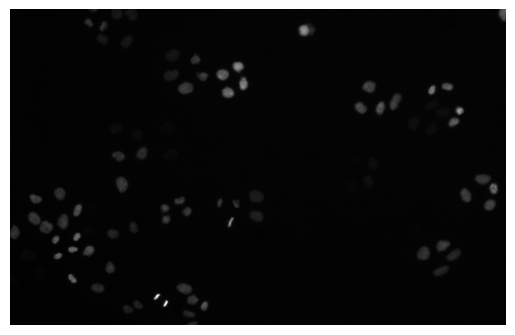

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile as tiff
import torch
from src.my_utils.configs import TRAIN_DATA_HELA, TRAIN_SEG_DATA_HELA
from torch.utils.data import Dataset
from torchvision import transforms


class VxmVideoDataset(Dataset):
    """PyTorch Dataset for VoxelMorph registration data on video."""

    def __init__(self, video_path, seg_path=None, max_gap=20, augment=False) -> None:
        """Parameters

        video_path : str
            Path to the video frames.
        seg_path : str
            Path to the segmentation frames (optional).
        max_gap : int
            Maximum gap between the two frames to select for registration (default: 20).
        augment : bool
            Apply augmentations if True.
        """
        self.video_path = Path(video_path)
        self.seg_path = Path(seg_path) if seg_path is not None else None
        self.get_path_list()
        self.augment = augment
        self.transform = self.get_transforms(n=len(self.frames_path_list))
        if not max_gap < len(self.frames_path_list) // 2:
            raise ValueError(
                f"max_gap {max_gap} should be smaller than frames number // 2 {len(self.frames_path_list) // 2}."
            )
        self.max_gap = max_gap

    def __getitem__(self, idx):
        """Normalize video and generate pairs of frame from a single video.

        dict
            A dictionary containing the source and target frames.
        """
        # Select 2 frames with a random gap (maximum 10 frames gap)20
        gap = np.random.randint(-self.max_gap, self.max_gap + 1)  # noqa: NPY002
        if gap == 0:
            gap = 1
        idx1 = idx % (len(self.frames_path_list) - 1)  # to avoid out of index error when selecting pairs of frames
        idx2 = idx1 - gap if (idx1 + gap > (len(self.frames_path_list) - 1) or idx1 + gap < 0) else idx1 + gap

        source_img = tiff.imread(self.frames_path_list[idx1])
        target_img = tiff.imread(self.frames_path_list[idx2])

        # Normalisation + augmentation if augment
        source_img = self.transform(source_img)
        target_img = self.transform(target_img)

        # To tensor
        source = torch.from_numpy(source_img)
        target = torch.from_numpy(target_img)

        if self.seg_path is not None:
            source_seg = tiff.imread(self.seg_path_list[idx1])
            target_seg = tiff.imread(self.seg_path_list[idx2])
            source_seg = torch.from_numpy(source_seg)
            target_seg = torch.from_numpy(target_seg)
            return {"source": source, "target": target, "source_seg": source_seg, "target_seg": target_seg}

        return {"source": source, "target": target}

    def get_transforms(self, n):
        """Get global min and global max from n frames and return normalisation and transformation functions."""
        global_min = np.min(tiff.imread(str(self.frames_path_list[0])))
        global_max = np.max(tiff.imread(str(self.frames_path_list[0])))

        for i in range(1, n):
            current_min = np.min(tiff.imread(str(self.frames_path_list[i])))
            current_max = np.max(tiff.imread(str(self.frames_path_list[i])))

            global_min = min(global_min, current_min)
            global_max = max(global_max, current_max)

        def normalise(frame):
            return (frame - global_min) / (global_max - global_min)

        # video_sample = [tiff.imread(str(self.frames_path_list[i])) for i in range(0, n, 20)]
        # global_mean = np.mean(video_sample)
        # global_std = np.std(video_sample)
        
        # def normalise(frame):
        #     return (frame - global_mean) / (global_std)

        base_transforms = [normalise]

        if self.augment:
            base_transforms += [transforms.RandomApply(transforms.ColorJitter, 0.3)]

        return transforms.Compose(base_transforms)

    def __len__(self):
        """Return nbr of paires per epoch."""
        return (
            len(self.frames_path_list) * 3  # To have more paires per epoch
        )

    def get_path_list(self):
        """Create a list with all the frame's path and segmentation's path."""
        self.frames_path_list = sorted(self.video_path.iterdir())
        if self.seg_path is not None:
            self.seg_path_list = sorted(self.seg_path.iterdir())

train_dataset = VxmVideoDataset(video_path=TRAIN_DATA_HELA, seg_path=TRAIN_SEG_DATA_HELA, augment=False)

idx=40
stop=41
while idx<stop:
    res = train_dataset.__getitem__(idx=idx)
    source = res["source"]
    target = res["target"]
    plt.imshow(source, cmap="gray")
    plt.axis("off")
    plt.savefig("hela.png")
    plt.show()
    idx += 4

# Visualize new class dataset with clas NormalizeMinMax and ThresholdTransform

In [43]:
import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision.transforms import v2


class ThresholdTransform(nn.Module):
    """Return binarised object with a threshold and in the same type."""
    def __init__(self, thr_1):
        super().__init__()
        self.thr = thr_1

    def forward(self, x):
        """Forward."""
        return (x > self.thr).to(x.dtype)  # do not change the data type

class NormalizeMinMax(nn.Module):
    """Return normalized tensor based on min, max."""
    def __init__(self, global_min, global_max, eps = 1e-7):
        super().__init__()
        self.min = global_min
        self.max = global_max
        self.eps = eps
    def forward(self,x):
        """Forward."""
        return (x - self.min)/(self.max - self.min + self.eps)


class VxmVideoDataset(Dataset):
    """PyTorch Dataset for VoxelMorph registration data on video."""

    def __init__(self, video_path, seg_path=None, max_gap=20, augment=False) -> None:
        """Parameters

        video_path : str
            Path to the video frames.
        seg_path : str
            Path to the segmentation frames (optional).
        max_gap : int
            Maximum gap between the two frames to select for registration (default: 20).
        augment : bool
            Apply augmentations if True.
        """
        self.video_path = Path(video_path)
        self.seg_path = Path(seg_path) if seg_path is not None else None
        self.get_path_list()
        self.augment = augment
        self.transform = self.get_transforms(n=len(self.frames_path_list))
        if not max_gap < len(self.frames_path_list) // 2:
            raise ValueError(
                f"max_gap {max_gap} should be smaller than frames number // 2 {len(self.frames_path_list) // 2}."
            )
        self.max_gap = max_gap

    def __getitem__(self, idx):
        """Normalize video and generate pairs of frame from a single video.

        dict
            A dictionary containing the source and target frames.
        """
        # Select 2 frames with a random gap (maximum 10 frames gap)
        gap = np.random.randint(-self.max_gap, self.max_gap + 1)  # noqa: NPY002
        if gap == 0:
            gap = 1
        idx1 = idx % (len(self.frames_path_list) - 1)  # to avoid out of index error when selecting pairs of frames
        idx2 = idx1 - gap if (idx1 + gap > (len(self.frames_path_list) - 1) or idx1 + gap < 0) else idx1 + gap

        source_img = tiff.imread(self.frames_path_list[idx1])
        target_img = tiff.imread(self.frames_path_list[idx2])

        # To tensor
        source = torch.from_numpy(source_img).float()
        target = torch.from_numpy(target_img).float()

        # Normalisation + augmentation if augment
        source = self.transform(source)
        target = self.transform(target)

        if self.seg_path is not None:
            source_seg = tiff.imread(self.seg_path_list[idx1])
            target_seg = tiff.imread(self.seg_path_list[idx2])
            source_seg = torch.from_numpy(source_seg)
            target_seg = torch.from_numpy(target_seg)
            return {"source": source, "target": target, "source_seg": source_seg, "target_seg": target_seg}

        return {"source": source, "target": target}

    def get_transforms(self, n):
        """Get global min and global max from n frames and return normalisation and transformation functions."""
        global_min = np.min(tiff.imread(str(self.frames_path_list[0])))
        global_max = np.max(tiff.imread(str(self.frames_path_list[0])))

        for i in range(1, n):
            current_min = np.min(tiff.imread(str(self.frames_path_list[i])))
            current_max = np.max(tiff.imread(str(self.frames_path_list[i])))

            global_min = min(global_min, current_min)
            global_max = max(global_max, current_max)

        base_transforms = [NormalizeMinMax(global_min=global_min, global_max=global_max)]

        if self.augment:
            # base_transforms += [v2.RandomApply(v2.ColorJitter, 0.3)]  # noqa: ERA001
            base_transforms += [ThresholdTransform(thr_1=0.05)]

        return v2.Compose(base_transforms)

    def __len__(self):
        """Return nbr of paires to train on per epoch."""
        return (
            len(self.frames_path_list) * 3  # To have more paires per epoch
        )

    def get_path_list(self):
        """Create a list with all the frame's path and segmentation's path."""
        self.frames_path_list = sorted(self.video_path.iterdir())
        if self.seg_path is not None:
            self.seg_path_list = sorted(self.seg_path.iterdir())

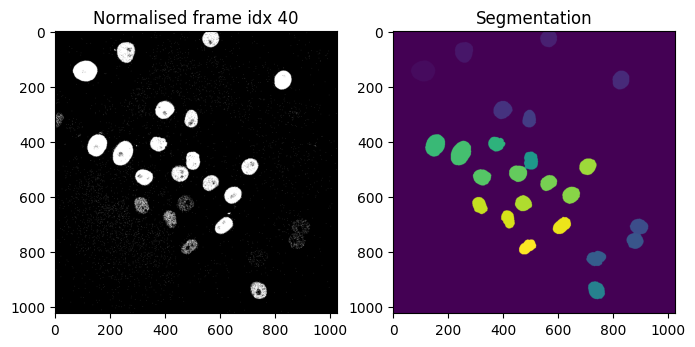

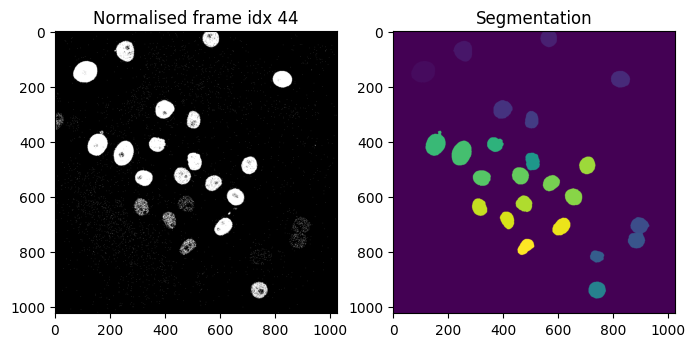

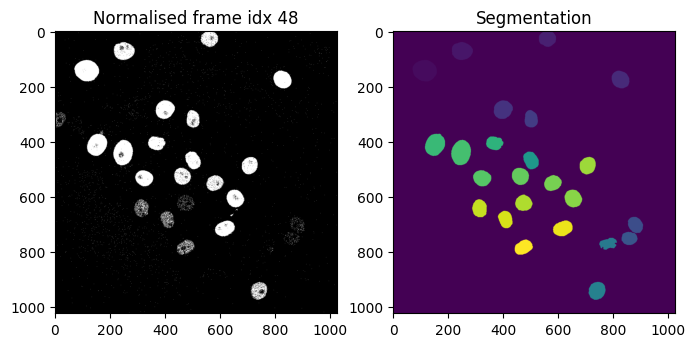

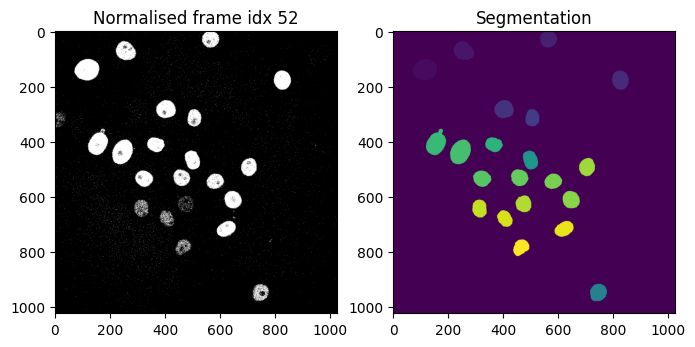

In [44]:
train_dataset = VxmVideoDataset(video_path=TRAIN_DATA, seg_path=TRAIN_SEG_DATA, augment=True)

idx=40
stop=53
while idx<stop:
    fig, ax = plt.subplots(1,2,figsize=(8,16))
    res = train_dataset.__getitem__(idx=idx)
    source = res["source"]
    source_seg = res["source_seg"]
    ax[0].imshow(source, cmap="gray")
    ax[0].set_title(f"Normalised frame idx {idx}")
    ax[1].imshow(source_seg)
    ax[1].set_title("Segmentation")
    plt.show()
    idx += 4

# Generation of gaussian frame

In [25]:
import os
import numpy as np
import tifffile
import cv2


def genererate_video_gaussienne(nb_frames=20, sigma=20.0):
    """
    Generate a sequence of Gaussian images that move linearly.
    """
    video_frames = []

    pos_start = np.array([100.0, 100.0])
    pos_fin = np.array([900.0, 900.0])

    deplacement_par_frame = (pos_fin - pos_start) / (nb_frames - 1)

    Y, X = np.indices((1024, 1024))

    for i in range(nb_frames):
        cx, cy = pos_start + i * deplacement_par_frame

        gaussienne = np.exp(-((X - cx)**2 + (Y - cy)**2) / (2 * sigma**2)).astype(np.float32)
        cercle = cv2.circle(np.zeros_like(gaussienne), (int(cx), int(cy)), int(sigma), color=1, thickness=-1).astype(np.float32)

        video_frames.append((cercle*255).astype(np.uint8))

    return video_frames, deplacement_par_frame

# 1. Générer les images
frames, flow_theorique = genererate_video_gaussienne(
    nb_frames=15, 
    sigma=50
)

dir = "data/gaussien_video"
os.makedirs(dir, exist_ok=True)


for i, frame in enumerate(frames):
    name = f"frame_{i:02d}.tif"
    complete_path = os.path.join(dir, name)

    tifffile.imwrite(complete_path, frame)


# Convert mask into gaussian

In [1]:
from skimage.measure import regionprops
import numpy as np

def mask_to_gaussian(segmentation, sigma_scale=0.5):
    """Convert a segmentation mask to a Gaussian heatmap.

    Parameters:
        segmentation: 2D array of shape (H, W) with integer labels for each cell.
        sigma_scale: Sigma for the Gaussian = radius * sigma_scale."""
    heatmap = np.zeros_like(segmentation, dtype=np.float32)
    y_grid, x_grid = np.indices(segmentation.shape)
    for region in regionprops(segmentation):
        if region.label == 0:
            continue
        y, x = region.centroid
        cell_sigma = (region.equivalent_diameter_area / 2) * sigma_scale
        cell_sigma = max(
            cell_sigma, 1
        )  # Ensure sigma is at least 1 to avoid very sharp peaks
        heatmap += np.exp(
            -((x_grid - x) ** 2 + (y_grid - y) ** 2) / (2 * cell_sigma**2)
        ).astype(np.float32)
    return heatmap

In [2]:
# To do once on segmentation dataset
from scripts.my_utils.configs import TRAIN_SEG_DATA
from pathlib import Path
import tifffile as tiff

path = Path(TRAIN_SEG_DATA)
video = sorted(path.iterdir())
out_path = path.parent / "SEG_HEATMAP"
out_path.mkdir(exist_ok=True)
for idx in range(len(video)):
    img = tiff.imread(video[idx])
    hm = mask_to_gaussian(img)
    tiff.imwrite(f"{str(out_path)}/heatmap_{idx:02d}.tif", hm)


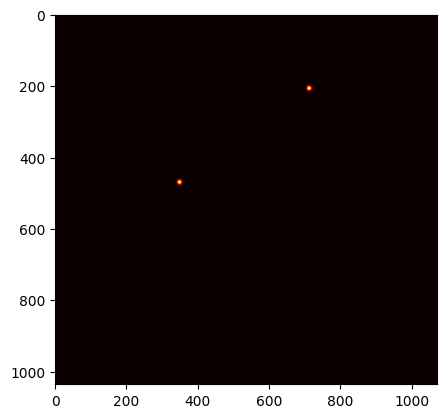

In [12]:
import matplotlib.pyplot as plt

out_path = "data/data/BF-C2DL-MuSC/SEG_HEATMAP"
img = tiff.imread(f"{str(out_path)}/heatmap_00.tif")
plt.imshow(img, cmap="hot")
plt.show()

# Visualisation des images réduites

Original shape: torch.Size([1, 1, 1010, 1010])
Original shape: torch.Size([1, 1, 1010, 1010]), Downsampled shape: torch.Size([1, 1, 126, 126])


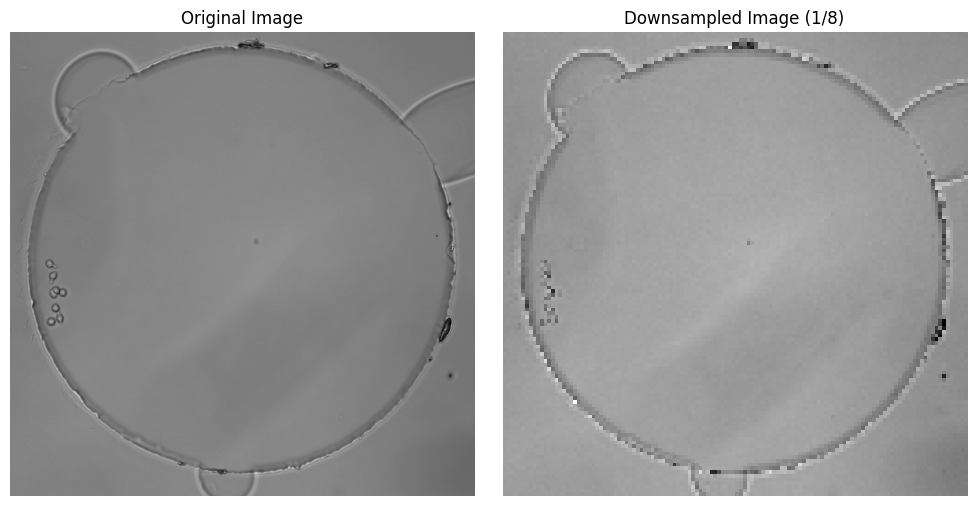

In [8]:
import torch.nn.functional as F
from scripts.my_utils.configs import TRAIN_DATA_HSC
from pathlib import Path
import tifffile as tiff
import torch
import matplotlib.pyplot as plt

img = tiff.imread(sorted(Path(TRAIN_DATA_HSC).iterdir())[180])
img = torch.from_numpy(img).unsqueeze(0).unsqueeze(0).float()

print(f"Original shape: {img.shape}")

img_down = F.interpolate(
            img, scale_factor=1/8, mode="bilinear", align_corners=False
        )

print(f"Original shape: {img.shape}, Downsampled shape: {img_down.shape}")
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img.squeeze().squeeze().numpy(), cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(img_down.squeeze().squeeze().numpy(), cmap="gray")
plt.title("Downsampled Image (1/8)")
plt.axis("off")
plt.tight_layout()
plt.show()


# Spatial transformers test

In [5]:
# CODE RAFT

import numpy as np

def make_colorwheel():
    """
    Generates a color wheel for optical flow visualization as presented in:
        Baker et al. "A Database and Evaluation Methodology for Optical Flow" (ICCV, 2007)
        URL: http://vision.middlebury.edu/flow/flowEval-iccv07.pdf

    Code follows the original C++ source code of Daniel Scharstein.
    Code follows the the Matlab source code of Deqing Sun.

    Returns:
        np.ndarray: Color wheel
    """

    RY = 15
    YG = 6
    GC = 4
    CB = 11
    BM = 13
    MR = 6

    ncols = RY + YG + GC + CB + BM + MR
    colorwheel = np.zeros((ncols, 3))
    col = 0

    # RY
    colorwheel[0:RY, 0] = 255
    colorwheel[0:RY, 1] = np.floor(255*np.arange(0,RY)/RY)
    col = col+RY
    # YG
    colorwheel[col:col+YG, 0] = 255 - np.floor(255*np.arange(0,YG)/YG)
    colorwheel[col:col+YG, 1] = 255
    col = col+YG
    # GC
    colorwheel[col:col+GC, 1] = 255
    colorwheel[col:col+GC, 2] = np.floor(255*np.arange(0,GC)/GC)
    col = col+GC
    # CB
    colorwheel[col:col+CB, 1] = 255 - np.floor(255*np.arange(CB)/CB)
    colorwheel[col:col+CB, 2] = 255
    col = col+CB
    # BM
    colorwheel[col:col+BM, 2] = 255
    colorwheel[col:col+BM, 0] = np.floor(255*np.arange(0,BM)/BM)
    col = col+BM
    # MR
    colorwheel[col:col+MR, 2] = 255 - np.floor(255*np.arange(MR)/MR)
    colorwheel[col:col+MR, 0] = 255
    return colorwheel


def flow_uv_to_colors(u, v, convert_to_bgr=False):
    """
    Applies the flow color wheel to (possibly clipped) flow components u and v.

    According to the C++ source code of Daniel Scharstein
    According to the Matlab source code of Deqing Sun

    Args:
        u (np.ndarray): Input horizontal flow of shape [H,W]
        v (np.ndarray): Input vertical flow of shape [H,W]
        convert_to_bgr (bool, optional): Convert output image to BGR. Defaults to False.

    Returns:
        np.ndarray: Flow visualization image of shape [H,W,3]
    """
    flow_image = np.zeros((u.shape[0], u.shape[1], 3), np.uint8)
    colorwheel = make_colorwheel()  # shape [55x3]
    ncols = colorwheel.shape[0]
    rad = np.sqrt(np.square(u) + np.square(v))
    a = np.arctan2(-v, -u)/np.pi
    fk = (a+1) / 2*(ncols-1)
    k0 = np.floor(fk).astype(np.int32)
    k1 = k0 + 1
    k1[k1 == ncols] = 0
    f = fk - k0
    for i in range(colorwheel.shape[1]):
        tmp = colorwheel[:,i]
        col0 = tmp[k0] / 255.0
        col1 = tmp[k1] / 255.0
        col = (1-f)*col0 + f*col1
        idx = (rad <= 1)
        col[idx]  = 1 - rad[idx] * (1-col[idx])
        col[~idx] = col[~idx] * 0.75   # out of range
        # Note the 2-i => BGR instead of RGB
        ch_idx = 2-i if convert_to_bgr else i
        flow_image[:,:,ch_idx] = np.floor(255 * col)
    return flow_image


def flow_to_image(flow_uv, clip_flow=None, convert_to_bgr=False):
    """
    Expects a two dimensional flow image of shape.

    Args:
        flow_uv (np.ndarray): Flow UV image of shape [H,W,2]
        clip_flow (float, optional): Clip maximum of flow values. Defaults to None.
        convert_to_bgr (bool, optional): Convert output image to BGR. Defaults to False.

    Returns:
        np.ndarray: Flow visualization image of shape [H,W,3]
    """
    assert flow_uv.ndim == 3, 'input flow must have three dimensions'
    assert flow_uv.shape[2] == 2, 'input flow must have shape [H,W,2]'
    if clip_flow is not None:
        flow_uv = np.clip(flow_uv, 0, clip_flow)
    u = flow_uv[:,:,0]
    v = flow_uv[:,:,1]
    rad = np.sqrt(np.square(u) + np.square(v))
    rad_max = np.max(rad)
    epsilon = 1e-5
    u = u / (rad_max + epsilon)
    v = v / (rad_max + epsilon)
    return flow_uv_to_colors(u, v, convert_to_bgr)



def viz(flo, ax=None):
    """Visualisation of flow, code from raft."""
    flo = flo.squeeze(0).permute(1, 2, 0).cpu().numpy()

    # map flow to rgb image
    flo = flow_to_image(flo)
    if ax is None:
        plt.imshow(flo)
    else:
        ax.imshow(flo)

In [10]:
import torch

def generate_dummy_flows(batch_size=1, height=64, width=64, displacement_x=5.0):
    """
    Génère un flux optique constant vers la droite et son inverse vers la gauche.
    
    Args:
        batch_size (int): Taille du batch.
        height (int): Hauteur spatiale de la frame.
        width (int): Largeur spatiale de la frame.
        displacement_x (float): Valeur du déplacement en pixels.
        
    Returns:
        forward_flow (torch.Tensor): Flux vers la droite de shape (B, 2, H, W).
        backward_flow (torch.Tensor): Flux vers la gauche de shape (B, 2, H, W).
    """
    # Initialisation des tenseurs de flux avec des zéros
    forward_flow = torch.zeros((batch_size, 2, height, width), dtype=torch.float32)
    backward_flow = torch.zeros((batch_size, 2, height, width), dtype=torch.float32)
    
    # Canal 0 : axe X (horizontal)
    # Canal 1 : axe Y (vertical)
    
    # Mouvement vers la droite : déplacement positif sur l'axe X
    forward_flow[:, 1, :, :] = displacement_x
    
    # Mouvement vers la gauche : déplacement négatif sur l'axe X
    backward_flow[:, 1, :, :] = -displacement_x
    
    # Le mouvement en Y (canal 1) reste à 0 pour un flux purement horizontal
    
    return forward_flow, backward_flow

# --- Exemple d'utilisation ---
B, H, W = 1, 128, 128
deplacement_pixels = 10.0


tensor(0.)


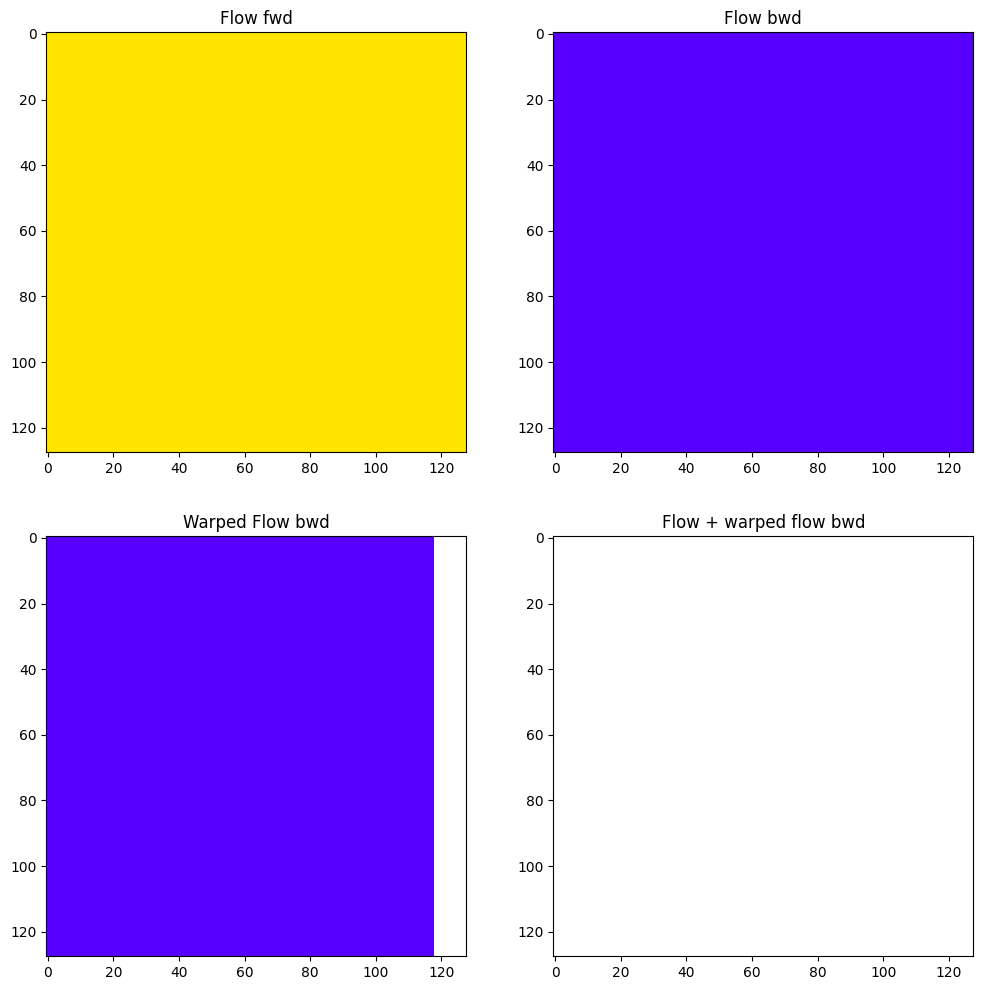

In [14]:
import voxelmorph_folder.voxelmorph as vxm
import matplotlib.pyplot as plt

spatial_transformer = vxm.nn.modules.SpatialTransformer(
            interpolation_mode="linear"
        )

flow_fwd, flow_bwd = generate_dummy_flows(B, H, W, deplacement_pixels)

warped_flow_bwd = spatial_transformer(flow_bwd, flow_fwd)
flow_sum = flow_fwd + flow_bwd
cycle_loss = torch.norm(flow_sum, p=2, dim=1).mean()

print(cycle_loss)

fig, ax = plt.subplots(2, 2, figsize=(12, 12))
plt.subplot(2, 2, 1)
ax[0, 0].set_title("Flow fwd")
viz(flo=flow_fwd, ax=ax[0, 0])
plt.subplot(2, 2, 2)
ax[0, 1].set_title("Flow bwd")
viz(flo=flow_bwd, ax=ax[0, 1])
plt.subplot(2, 2, 3)
ax[1, 0].set_title("Warped Flow bwd")
viz(flo=warped_flow_bwd, ax=ax[1, 0])
plt.subplot(2, 2, 4)
ax[1, 1].set_title("Flow + warped flow bwd")
viz(flo=flow_sum, ax=ax[1, 1])

In [4]:
hsc = (0.902 - 0.742)/(1-0.742)
musc = (0.774 - 0.570)/(1 - 0.570)
gowt = (0.983 - 0.937)/(1 - 0.937)
print(hsc, musc, gowt)
hsc = (0.81 - 0.742)/(1-0.742)
musc = (0.73 - 0.570)/(1 - 0.570)
gowt = (0.979 - 0.937)/(1 - 0.937)
print(hsc, musc, gowt)
hsc = (0.863 - 0.742)/(1-0.742)
musc = (0.65 - 0.570)/(1 - 0.570)
gowt = (0.973 - 0.937)/(1 - 0.937)
print(hsc, musc, gowt)

0.62015503875969 0.4744186046511629 0.7301587301587297
0.26356589147286846 0.372093023255814 0.6666666666666661
0.4689922480620155 0.1860465116279071 0.5714285714285706


In [3]:
idx1 = 0
limits = [0, 2, 8]


video_idx = 0
limit = limits[video_idx]
while idx1 >= limit:
    video_idx += 1
    limit = limits[video_idx]
start_idx = limits[video_idx - 1]
end_idx = limits[video_idx] - 1

print(video_idx)


1


In [3]:
import timm

print(timm.list_models('*swin*'))

['hiera_base_abswin_256', 'hiera_small_abswin_256', 'swin_base_patch4_window7_224', 'swin_base_patch4_window12_384', 'swin_large_patch4_window7_224', 'swin_large_patch4_window12_384', 'swin_s3_base_224', 'swin_s3_small_224', 'swin_s3_tiny_224', 'swin_small_patch4_window7_224', 'swin_tiny_patch4_window7_224', 'swinv2_base_window8_256', 'swinv2_base_window12_192', 'swinv2_base_window12to16_192to256', 'swinv2_base_window12to24_192to384', 'swinv2_base_window16_256', 'swinv2_cr_base_224', 'swinv2_cr_base_384', 'swinv2_cr_base_ns_224', 'swinv2_cr_giant_224', 'swinv2_cr_giant_384', 'swinv2_cr_huge_224', 'swinv2_cr_huge_384', 'swinv2_cr_large_224', 'swinv2_cr_large_384', 'swinv2_cr_small_224', 'swinv2_cr_small_384', 'swinv2_cr_small_ns_224', 'swinv2_cr_small_ns_256', 'swinv2_cr_tiny_224', 'swinv2_cr_tiny_384', 'swinv2_cr_tiny_ns_224', 'swinv2_large_window12_192', 'swinv2_large_window12to16_192to256', 'swinv2_large_window12to24_192to384', 'swinv2_small_window8_256', 'swinv2_small_window16_256',

In [8]:
import datetime
import time

timestamp = datetime.datetime.now(tz=datetime.UTC)
time.sleep(2)
end_timestamp = datetime.datetime.now(tz=datetime.UTC) #.strftime("%Y%m%d_%H%M%S")
timeee = (end_timestamp - timestamp).seconds
print(timeee)

2


In [ ]:
from pathlib import Path

import numpy as np
import tifffile as tiff
from cellpose import models
from cellpose.io import imread

from src.my_utils import configs

video_path = configs.TRAIN_DATA_GOWT

output_path = Path(video_path).parent / "CELLPOSE_SEG"

if not output_path.exists():
    # use Cellpose to create segmentations
    output_path.mkdir(parents=True, exist_ok=True)
    frames_path_list = sorted(Path(video_path).iterdir())
    imgs = [imread(f) for f in frames_path_list]

    model = models.CellposeModel(gpu=True)

    masks, _, _ = model.eval(
        imgs, flow_threshold=0.4, cellprob_threshold=0.0
    )
    for idx, mask in enumerate(masks):
        mask_binary = (mask > 0).astype(np.float32)
        tiff.imwrite(
            output_path / f"cellpose_{idx:04d}.tif", mask_binary
        )

# Cellpose vs gt

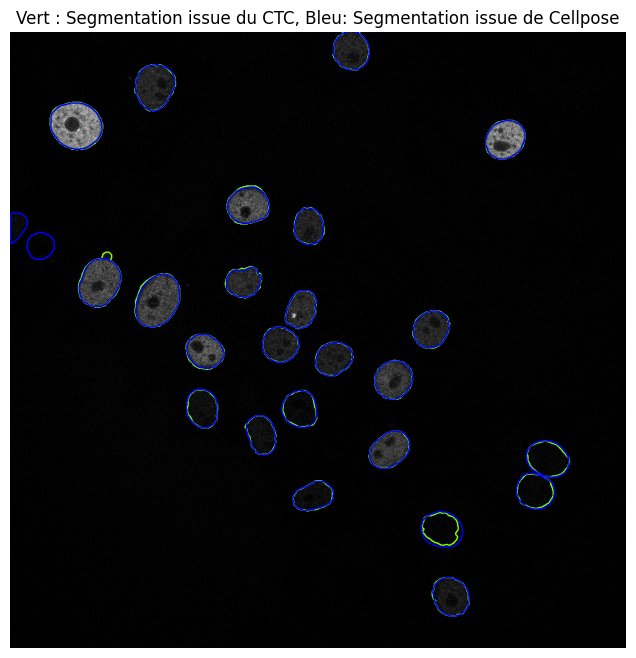

In [21]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import tifffile as tiff

img_path_list = sorted(Path("data/data/Fluo-N2DH-GOWT1_train/01").iterdir())
gt_seg_path_list = sorted(Path("data/data/Fluo-N2DH-GOWT1_train/01_ERR_SEG_TRA").iterdir())
cellpose_seg_path_list = sorted(Path("data/data/Fluo-N2DH-GOWT1_train/CELLPOSE_SEG").iterdir())

idx = 32

img = tiff.imread(img_path_list[idx])
gt_seg= tiff.imread(gt_seg_path_list[idx])
cellpose_seg = tiff.imread(cellpose_seg_path_list[idx])

figure = plt.figure(figsize=(8, 8))
plt.imshow(img, cmap="gray")
plt.title(
    "Vert : Segmentation issue du CTC, Bleu: Segmentation issue de Cellpose"
)
gt_seg= np.where(gt_seg > 0, 1, 0)
cellpose_seg = np.where(cellpose_seg > 0, 1, 0)
plt.contour(gt_seg, levels=[0.5], colors="chartreuse", linewidths=1)
plt.contour(cellpose_seg, levels=[0.5], colors="blue", linewidths=1)
plt.axis("off")
figure.savefig("comparaison_cellpose_gt.png")


# figure = plt.figure(figsize=(8, 8))
# plt.imshow(seg_moving, cmap="gray")
# figure.savefig("segmentation_musc_0.png")


# cv2.imwrite("segmentation_musc_0.png", seg_moving)
# cv2.imwrite("segmentation_musc_1.png", seg_fixed)

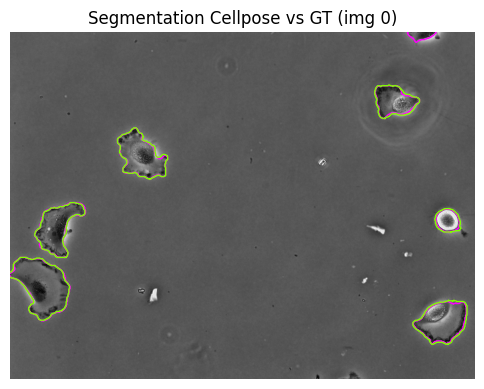

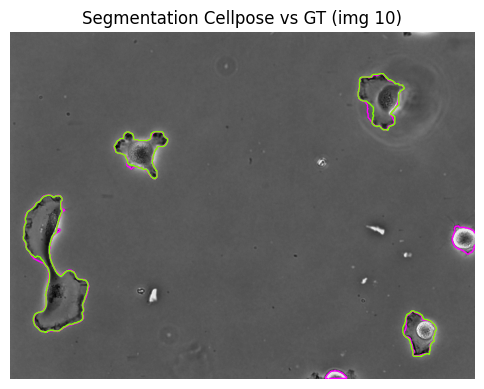

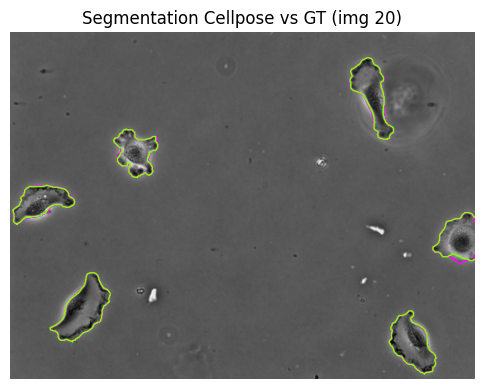

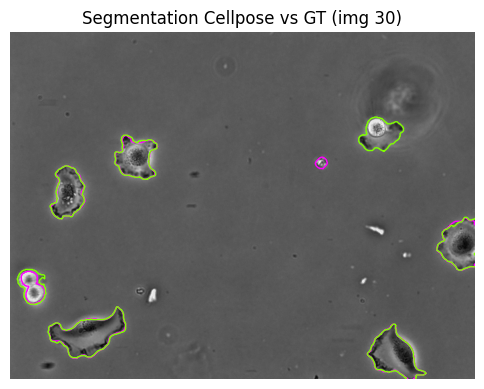

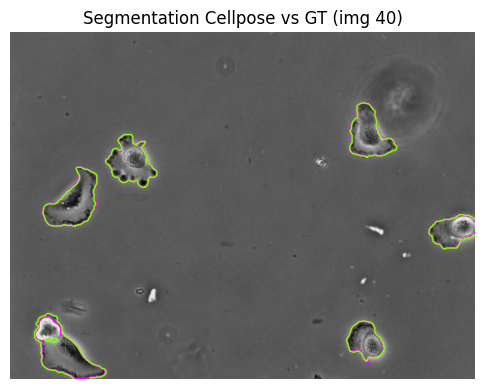

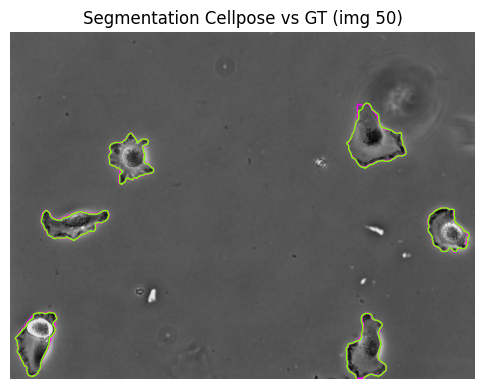

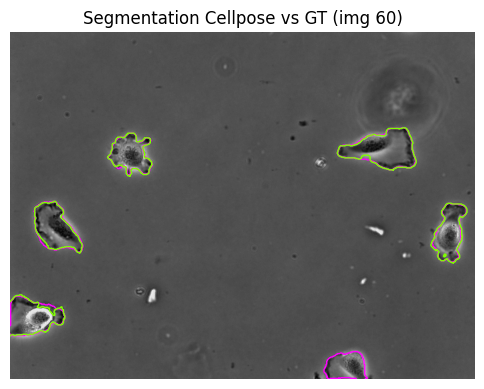

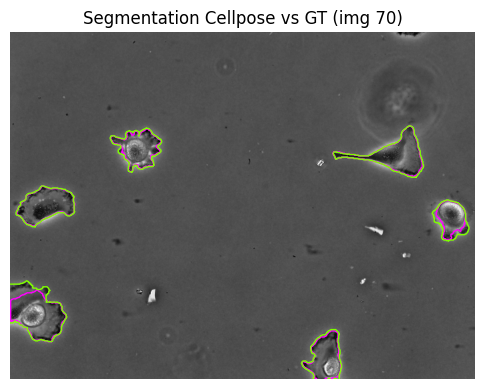

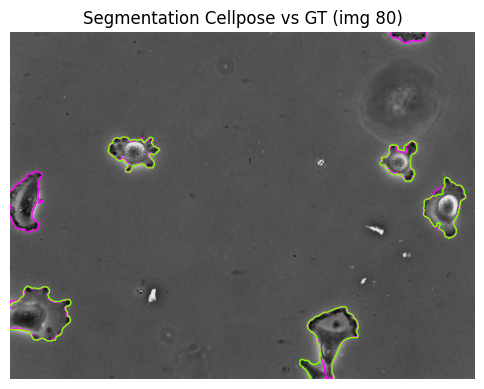

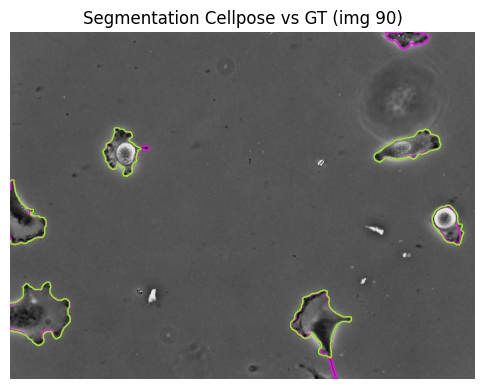

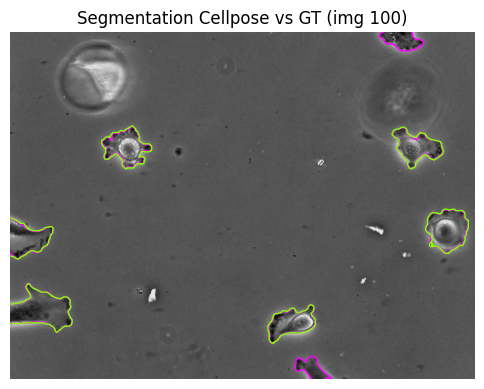

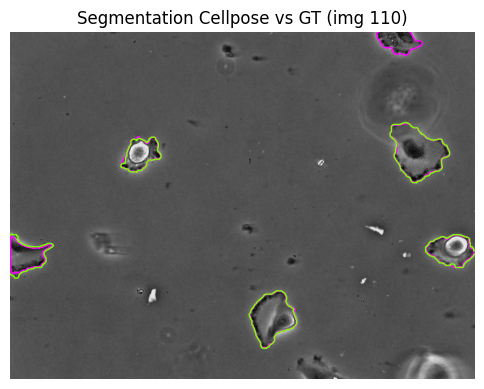

Mean Dice score: 0.9310


In [41]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy
import tifffile as tiff
import voxelmorph as vxm
from cellpose import models
from cellpose.io import imread
from PIL import Image
from skimage.measure import find_contours

from src.my_utils import configs

DATA = "U373"
trfs_seg = np.array(Image.open("outputs/transflowseg/output_20260731_181631/results_gap1/viz/segmentation_result_for_0.png"))


def interpole_and_pad(image, target_shape=(1024, 1024)):
    """Interpolate and pad image to target shape."""
    if image.shape[0] > target_shape[0] or image.shape[1] > target_shape[1]:
        dim_factors = [
            target_shape[0] / image.shape[0],
            target_shape[1] / image.shape[1],
        ]
        image = scipy.ndimage.interpolation.zoom(image, dim_factors, order=0)
    return vxm.py.utils.pad(image, target_shape)[0]

def evaluate_segmentation(segmentation_pred, segmentation_gt):
    """Evaluate the segmentation results."""
    # Load segmentation masks
    seg_pred = interpole_and_pad(segmentation_pred, [configs.HEIGHT, configs.WIDTH])
    seg_gt = interpole_and_pad(segmentation_gt, [configs.HEIGHT, configs.WIDTH])
    # Binarise
    seg_gt = seg_gt > 0
    seg_pred = (seg_pred > 0.5).astype(int)
    # Compute Dice score
    dice = vxm.py.utils.dice(seg_pred, seg_gt, include_zero=False)
    score = np.mean(dice)
    return score

def plot_contours(seg, color, ax=None):
    if ax is None:
        ax = plt.gca()

    labels = np.unique(seg)

    for label in labels:
        if label == 0:
            continue
        mask = seg == label
        contours = find_contours(mask, level=0.5)
        for contour in contours:
            # contour[:, 1] = X, contour[:, 0] = Y
            ax.plot(contour[:, 1], contour[:, 0], color=color, linewidth=1)

video_path = getattr(configs, f"TEST_DATA_{DATA}")
video_path_list = sorted(Path(video_path).iterdir())
output_path = Path(video_path).parent / "CELLPOSE_SEG_02"

if not output_path.exists():
    # use Cellpose to create segmentations
    output_path.mkdir(parents=True, exist_ok=True)
    frames_path_list = sorted(Path(video_path).iterdir())
    imgs = [imread(f) for f in frames_path_list]

    model = models.CellposeModel(gpu=True)

    masks, _, _ = model.eval(
        imgs, flow_threshold=0.4, cellprob_threshold=0.0
    )
    for idx, mask in enumerate(masks):
        mask_binary = (mask > 0).astype(np.float32)
        tiff.imwrite(
            output_path / f"cellpose_{idx:04d}.tif", mask_binary
        )

gt_seg_path_list = sorted(Path(getattr(configs, f"TEST_SEG_DATA_{DATA}")).iterdir())
cellpose_seg_path_list = sorted(Path(output_path).iterdir())


if len(gt_seg_path_list) != len(cellpose_seg_path_list):
    print(gt_seg_path_list)
    raise ValueError(f"The number of ground truth and predicted segmentations must be the same, got {len(gt_seg_path_list)} and {len(cellpose_seg_path_list)}")

scores = []
for idx in range(len(gt_seg_path_list)):
    gt_seg = tiff.imread(gt_seg_path_list[idx])
    gt_seg = gt_seg > 0
    cellpose_seg = tiff.imread(cellpose_seg_path_list[idx])
    score = evaluate_segmentation(cellpose_seg, gt_seg)
    scores.append(score)

    # To visualise seg evaluation
    if idx % 10 == 0:
        img = tiff.imread(video_path_list[idx])
        fig = plt.figure(figsize=(6,6))
        plt.imshow(img, cmap="gray")
        plt.title(f"Segmentation Cellpose vs GT (img {idx})")
        plot_contours(cellpose_seg, "magenta")
        plot_contours(gt_seg, "chartreuse")
        plt.axis("off")
        plt.show()
print(f"Mean Dice score: {np.mean(scores):.4f}")


# Generation video

In [9]:
from pathlib import Path

import cv2
import numpy as np

from src.my_utils import configs

DATA = "U373"
video_path = getattr(configs, f"TRAIN_DATA_{DATA}")
video_path_list = sorted(Path(video_path).iterdir())[-40:] 

premiere_image = cv2.imread(video_path_list[0], cv2.IMREAD_ANYDEPTH)
hauteur, largeur = premiere_image.shape[:2]

fps = 10
fourcc = cv2.VideoWriter_fourcc(*'mp4v') # Codec pour générer un fichier .mp4
out = cv2.VideoWriter('dynamique_cellules_opencv.mp4', fourcc, fps, (largeur, hauteur))

for path in video_path_list:
    img = cv2.imread(path, cv2.IMREAD_ANYDEPTH)
    
    # # 4. Normalisation et conversion en 8-bits
    # # Si l'image est en 16-bits, cv2.normalize va étirer les pixels pour utiliser 
    # # tout le spectre (0 à 255) : cela va grandement améliorer le contraste de tes cellules !
    # if img.dtype == np.uint16 or img.dtype == np.float32:
    #     img = cv2.normalize(img, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    if len(img.shape) == 2: # Si c'est en niveaux de gris (1 canal)
        img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    else:
        img_bgr = img
        
    # Ajouter la frame au fichier vidéo
    out.write(img_bgr)

# 6. Très important : libérer le fichier vidéo à la fin
out.release()